In [1]:
# ============================================================
# STEP 1f — Use the FULL path to the project folder.
#
# Earlier the notebook lost track of the folder after a kernel
# restart. Writing the complete address removes that problem:
# it no longer matters where the notebook itself is running.
# ============================================================

import os, zipfile

# The full address of your Paper 3 folder.
# The r"..." tells Python to read the backslashes literally.
FOLDER = r"C:\Users\Laptop Solutions\OneDrive\Desktop\paper 3"

zip_path = os.path.join(FOLDER, "predict+students+dropout+and+academic+success.zip")
csv_path = os.path.join(FOLDER, "data.csv")

print("Project folder :", FOLDER)
print("Folder exists  :", os.path.isdir(FOLDER))
print("Zip exists     :", os.path.isfile(zip_path))

# Extract the zip INTO that folder, using the full address.
if os.path.isfile(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        print("\nInside the zip:", z.namelist())
        z.extractall(FOLDER)
    print("Extracted.")
else:
    print("\n>>> Zip not found at that address. Check the folder name.")

# Show what is in the project folder now.
print("\nFiles in the project folder:")
for f in sorted(os.listdir(FOLDER)):
    print("   ", f)

print("\ndata.csv ready :", os.path.isfile(csv_path))

Project folder : C:\Users\Laptop Solutions\OneDrive\Desktop\paper 3
Folder exists  : True
Zip exists     : True

Inside the zip: ['data.csv']
Extracted.

Files in the project folder:
    PAPER 3.html
    PAPER_3.pdf
    Paper3_Guide_Urdu.docx
    References_Checklist.docx
    applsci-16-08915.pdf
    data.csv
    figures
    mathematics-14-00626.pdf
    paper.tex
    predict+students+dropout+and+academic+success.zip

data.csv ready : True


In [2]:
# ============================================================
# CELL 2 — Load the dataset and verify it.
#
# This produces the numbers that become Table 1 of the paper.
# No model is trained here. We are only proving that the data
# is exactly what the paper will claim it is.
# ============================================================

import pandas as pd

csv_path = os.path.join(FOLDER, "data.csv")   # full address, from Cell 1

# --- Read the file -------------------------------------------------
# Three quirks in this particular file, all of which must be handled:
#   sep=";"              -> the columns are separated by semicolons, not commas
#   encoding="utf-8-sig" -> the file starts with a hidden BOM character
#   .strip()             -> one column name ends with a stray tab character
df = pd.read_csv(csv_path, sep=";", encoding="utf-8-sig")
df.columns = [c.strip() for c in df.columns]

# --- Size ----------------------------------------------------------
print("=" * 58)
print("TABLE 1 — DATASET DESCRIPTION")
print("=" * 58)
print(f"Records (students) : {df.shape[0]}")
print(f"Columns            : {df.shape[1]}   ({df.shape[1]-1} features + 1 target)")

# --- Data quality --------------------------------------------------
print(f"Missing values     : {df.isnull().sum().sum()}")
print(f"Duplicate rows     : {df.duplicated().sum()}")

# --- Class balance (the most important part) -----------------------
print("\nTarget class distribution:")
counts = df["Target"].value_counts()
for cls in ["Dropout", "Enrolled", "Graduate"]:
    n = counts[cls]
    print(f"   {cls:<10} {n:>5}   ({n/len(df)*100:5.2f}%)")

# --- Sanity check: are the values sensible? ------------------------
print("\nSanity check:")
print(f"   Age at enrollment : {df['Age at enrollment'].min()} - {df['Age at enrollment'].max()}")
print(f"   Admission grade   : {df['Admission grade'].min()} - {df['Admission grade'].max()}")
print(f"   Course codes      : {df['Course'].nunique()} different programmes")

# --- Separate features from target, ready for the next step --------
X = df.drop(columns=["Target"])   # the 36 inputs
y = df["Target"]                  # the label we predict

print(f"\nX shape: {X.shape}    y shape: {y.shape}")
print("\nCell 2 done.")

TABLE 1 — DATASET DESCRIPTION
Records (students) : 4424
Columns            : 37   (36 features + 1 target)
Missing values     : 0
Duplicate rows     : 0

Target class distribution:
   Dropout     1421   (32.12%)
   Enrolled     794   (17.95%)
   Graduate    2209   (49.93%)

Sanity check:
   Age at enrollment : 17 - 70
   Admission grade   : 95.0 - 190.0
   Course codes      : 17 different programmes

X shape: (4424, 36)    y shape: (4424,)

Cell 2 done.


In [3]:
# ============================================================
# CELL 3 — Split the data three ways: train / calibration / test
#
# This is the heart of split conformal prediction. An ordinary
# ML paper splits the data in two (train / test). We need THREE
# parts, and the reason is the whole point of the method.
# ============================================================

from sklearn.model_selection import train_test_split

# --- Frozen settings. Every number in the paper comes from these. ---
SEED  = 42     # controls the random split, so results are reproducible
ALPHA = 0.10   # we promise 90% coverage  (coverage = 1 - ALPHA)

# --- First cut: 60% train, 40% held back ---------------------------
# stratify=y keeps the three classes in the same proportion in
# every part. Without it, the small Enrolled class could end up
# badly represented purely by chance.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)

# --- Second cut: split that 40% into 20% calibration + 20% test ----
X_calib, X_test, y_calib, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print("=" * 58)
print("THREE-WAY SPLIT")
print("=" * 58)
print(f"Train       : {len(y_train):>5} students   (model learns from these)")
print(f"Calibration : {len(y_calib):>5} students   (sets the guarantee threshold)")
print(f"Test        : {len(y_test):>5} students   (only for measuring)")
print(f"Total       : {len(y_train)+len(y_calib)+len(y_test):>5}")

# --- Per-class counts. These matter a lot later. -------------------
print("\nClass counts in each part:")
print(f"   {'class':<10}{'train':>8}{'calib':>8}{'test':>8}")
for cls in ["Dropout", "Enrolled", "Graduate"]:
    print(f"   {cls:<10}{(y_train==cls).sum():>8}{(y_calib==cls).sum():>8}{(y_test==cls).sum():>8}")

print("\nCell 3 done.")

THREE-WAY SPLIT
Train       :  2654 students   (model learns from these)
Calibration :   885 students   (sets the guarantee threshold)
Test        :   885 students   (only for measuring)
Total       :  4424

Class counts in each part:
   class        train   calib    test
   Dropout        853     284     284
   Enrolled       476     159     159
   Graduate      1325     442     442

Cell 3 done.


In [4]:
# ============================================================
# CELL 4 — Train baseline models (this becomes Table 2)
#
# Two purposes:
#   1. Show that our model is a reasonable one, so nobody can
#      say the coverage problem is just a bad model.
#   2. Choose the model that conformal prediction will wrap.
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

N_TREES = 500   # frozen setting, used everywhere in the paper

models = {
    # Logistic regression needs its inputs on a common scale,
    # so we chain a scaler in front of it.
    "Logistic Regression":  make_pipeline(StandardScaler(),
                                          LogisticRegression(max_iter=3000, random_state=SEED)),
    "Random Forest":        RandomForestClassifier(n_estimators=N_TREES,
                                                   random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
}

print("=" * 58)
print("TABLE 2 — BASELINE MODELS (trained on train, measured on test)")
print("=" * 58)
print(f"{'model':<24}{'accuracy':>10}{'macro-F1':>11}")

fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)              # learn from the training part only
    pred = model.predict(X_test)             # predict the untouched test part
    fitted[name] = model
    acc = accuracy_score(y_test, pred) * 100
    f1  = f1_score(y_test, pred, average="macro")   # macro = all classes count equally
    print(f"{name:<24}{acc:>9.2f}%{f1:>11.4f}")

# --- Now look INSIDE the Random Forest, class by class -------------
# Accuracy alone hides what happens to each class separately.
rf = fitted["Random Forest"]
print("\n" + "=" * 58)
print("PER-CLASS BREAKDOWN — Random Forest")
print("=" * 58)
print(classification_report(y_test, rf.predict(X_test), digits=3))

print("Cell 4 done.")

TABLE 2 — BASELINE MODELS (trained on train, measured on test)
model                     accuracy   macro-F1
Logistic Regression         76.50%     0.6798
Random Forest               78.53%     0.7040
HistGradientBoosting        78.53%     0.7259

PER-CLASS BREAKDOWN — Random Forest
              precision    recall  f1-score   support

     Dropout      0.812     0.778     0.795       284
    Enrolled      0.629     0.352     0.452       159
    Graduate      0.798     0.946     0.865       442

    accuracy                          0.785       885
   macro avg      0.746     0.692     0.704       885
weighted avg      0.772     0.785     0.768       885

Cell 4 done.


In [5]:
# ============================================================
# CELL 5 — Conformal calibration: compute the threshold q-hat
#
# This is the mathematical core of the method. Everything the
# paper claims rests on this one number.
# ============================================================

import numpy as np

# --- 1. Ask the model for probabilities on the calibration set -----
# predict_proba gives a probability for EACH class, not just a label.
P_calib = rf.predict_proba(X_calib)          # shape: (885, 3)
class_order = rf.classes_                    # ['Dropout' 'Enrolled' 'Graduate']
print("Class order used by the model:", class_order)

# Map each true label to its column position in P_calib.
pos = {c: i for i, c in enumerate(class_order)}
y_calib_idx = np.array([pos[c] for c in y_calib])

# --- 2. Nonconformity score --------------------------------------
# For each calibration student we take the probability the model
# gave to their TRUE class, and subtract it from 1.
#
#        s_i  =  1 - p_hat( true class | student i )
#
# Small score  -> model was confident and right  -> "conforms"
# Large score  -> model gave the truth low probability -> "strange"
scores = 1 - P_calib[np.arange(len(y_calib_idx)), y_calib_idx]

# --- 3. The quantile, with the finite-sample correction ----------
n = len(scores)
k = int(np.ceil((n + 1) * (1 - ALPHA)))      # note (n+1), not n
q_hat = np.sort(scores)[k - 1]               # the k-th smallest score

print("\n" + "=" * 58)
print("CONFORMAL CALIBRATION")
print("=" * 58)
print(f"Calibration size n : {n}")
print(f"Target coverage    : {(1-ALPHA)*100:.0f}%   (alpha = {ALPHA})")
print(f"Rank needed  k     : ceil(({n}+1) x {1-ALPHA:.2f}) = ceil({(n+1)*(1-ALPHA):.1f}) = {k}")
print(f"Threshold  q_hat   : {q_hat:.4f}")

# --- 4. Diagnostic: how do the scores look per class? ------------
# One single q_hat is about to be applied to all three classes.
# This asks whether that is reasonable.
print("\nMean nonconformity score, by true class:")
for c in class_order:
    m = (y_calib.values == c)
    print(f"   {c:<10} mean {scores[m].mean():.4f}    median {np.median(scores[m]):.4f}    n = {m.sum()}")

print("\nCell 5 done.")

Class order used by the model: ['Dropout' 'Enrolled' 'Graduate']

CONFORMAL CALIBRATION
Calibration size n : 885
Target coverage    : 90%   (alpha = 0.1)
Rank needed  k     : ceil((885+1) x 0.90) = ceil(797.4) = 798
Threshold  q_hat   : 0.7600

Mean nonconformity score, by true class:
   Dropout    mean 0.3396    median 0.2520    n = 284
   Enrolled   mean 0.6477    median 0.6520    n = 159
   Graduate   mean 0.2498    median 0.1940    n = 442

Cell 5 done.


In [6]:
# ============================================================
# CELL 6 — Build prediction sets and measure coverage.
#          THIS IS THE MAIN RESULT OF THE PAPER (Table 3).
#
# Instead of one label per student, every student now gets a
# SET of labels. The promise is that the true label sits inside
# that set 90% of the time.
# ============================================================

# --- 1. Probabilities for the untouched test students -------------
P_test = rf.predict_proba(X_test)                 # shape: (885, 3)
y_test_idx = np.array([pos[c] for c in y_test])   # true class positions

# --- 2. Build the prediction sets ---------------------------------
# A class goes INTO the set if its nonconformity score is small
# enough, i.e.        1 - p(class) <= q_hat
# which is the same as   p(class) >= 1 - q_hat
sets = (1 - P_test) <= q_hat        # True/False for each student x class

print(f"A class enters the set if its probability >= {1 - q_hat:.2f}")

# --- 3. Did the true label land inside the set? -------------------
covered   = sets[np.arange(len(y_test_idx)), y_test_idx]   # True/False per student
set_sizes = sets.sum(axis=1)                               # how many labels per student

# --- 4. Coverage overall and for each class separately ------------
print("\n" + "=" * 62)
print("TABLE 3 — COVERAGE OF PREDICTION SETS   (promise = 90%)")
print("=" * 62)
print(f"{'class':<12}{'n':>6}{'coverage':>12}{'set size':>12}{'verdict':>14}")

overall_cov = covered.mean() * 100
print(f"{'Overall':<12}{len(y_test):>6}{overall_cov:>11.2f}%{set_sizes.mean():>12.3f}"
      f"{'KEPT' if overall_cov >= 90 else 'BROKEN':>14}")

for c in class_order:
    m = (y_test.values == c)
    cov_c = covered[m].mean() * 100
    print(f"{c:<12}{m.sum():>6}{cov_c:>11.2f}%{set_sizes[m].mean():>12.3f}"
          f"{'KEPT' if cov_c >= 90 else 'BROKEN':>14}")

# --- 5. How big are the sets? -------------------------------------
print("\nPrediction-set size distribution:")
for k_ in range(4):
    m = (set_sizes == k_)
    print(f"   |C(x)| = {k_} :  {m.sum():>4} students  ({m.mean()*100:5.1f}%)")

print("\nCell 6 done.")

A class enters the set if its probability >= 0.24

TABLE 3 — COVERAGE OF PREDICTION SETS   (promise = 90%)
class            n    coverage    set size       verdict
Overall        885      91.19%       1.472          KEPT
Dropout        284      88.38%       1.447        BROKEN
Enrolled       159      76.10%       1.931        BROKEN
Graduate       442      98.42%       1.324          KEPT

Prediction-set size distribution:
   |C(x)| = 0 :     0 students  (  0.0%)
   |C(x)| = 1 :   525 students  ( 59.3%)
   |C(x)| = 2 :   302 students  ( 34.1%)
   |C(x)| = 3 :    58 students  (  6.6%)

Cell 6 done.


In [7]:
# ============================================================
# CELL 7 — Repeat everything on 10 different random splits.
#
# THE DECISIVE TEST. Seed 42 alone proves nothing: the Enrolled
# failure could be an accident of one particular split. If it
# appears on all ten seeds, it is a property of the data and the
# paper stands. If it appears only on seed 42, there is no paper.
#
# Takes about a minute. Let it finish.
# ============================================================

def run_conformal(seed, alpha=0.10, n_trees=500):
    """Run the whole pipeline once, for one random split.
    Returns the coverage and mean set size for each class."""

    # --- same three-way split as Cell 3, but with this seed ---
    Xtr, Xtm, ytr, ytm = train_test_split(
        X, y, test_size=0.40, stratify=y, random_state=seed)
    Xcal, Xte, ycal, yte = train_test_split(
        Xtm, ytm, test_size=0.50, stratify=ytm, random_state=seed)

    # --- train ---
    model = RandomForestClassifier(n_estimators=n_trees,
                                   random_state=seed, n_jobs=-1).fit(Xtr, ytr)
    cls = model.classes_
    p = {c: i for i, c in enumerate(cls)}

    # --- calibrate (same maths as Cell 5) ---
    Pcal = model.predict_proba(Xcal)
    cal_idx = np.array([p[c] for c in ycal])
    s = 1 - Pcal[np.arange(len(cal_idx)), cal_idx]
    n_ = len(s)
    q = np.sort(s)[int(np.ceil((n_ + 1) * (1 - alpha))) - 1]

    # --- prediction sets on the test part (same as Cell 6) ---
    Pte = model.predict_proba(Xte)
    te_idx = np.array([p[c] for c in yte])
    S = (1 - Pte) <= q
    cov = S[np.arange(len(te_idx)), te_idx]

    out = {"Overall": (cov.mean() * 100, S.sum(1).mean())}
    for c in cls:
        m = (yte.values == c)
        out[c] = (cov[m].mean() * 100, S[m].sum(1).mean())
    return out


SEEDS = [42, 1, 7, 13, 21, 55, 77, 99, 123, 2024]

print("Running 10 seeds, please wait ...\n")
print("=" * 62)
print("PER-SEED COVERAGE   (promise = 90%)")
print("=" * 62)
print(f"{'seed':>7}{'Overall':>11}{'Dropout':>11}{'Enrolled':>11}{'Graduate':>11}")

results = {c: [] for c in ["Overall", "Dropout", "Enrolled", "Graduate"]}
for sd in SEEDS:
    r = run_conformal(sd)
    for c in results:
        results[c].append(r[c][0])
    print(f"{sd:>7}{r['Overall'][0]:>10.2f}%{r['Dropout'][0]:>10.2f}%"
          f"{r['Enrolled'][0]:>10.2f}%{r['Graduate'][0]:>10.2f}%")

# --- summary statistics: this is what goes in the paper ----------
print("\n" + "=" * 62)
print("SUMMARY OVER 10 SEEDS   <-- the paper's headline numbers")
print("=" * 62)
print(f"{'class':<11}{'mean':>9}{'sd':>8}{'min':>9}{'max':>9}{'seeds < 90%':>14}")
for c in ["Overall", "Dropout", "Enrolled", "Graduate"]:
    a = np.array(results[c])
    print(f"{c:<11}{a.mean():>8.2f}%{a.std(ddof=1):>8.2f}{a.min():>8.2f}%{a.max():>8.2f}%"
          f"{(a < 90).sum():>11}/10")

print("\nCell 7 done.")

Running 10 seeds, please wait ...

PER-SEED COVERAGE   (promise = 90%)
   seed    Overall    Dropout   Enrolled   Graduate
     42     91.19%     88.38%     76.10%     98.42%
      1     89.94%     85.92%     72.96%     98.64%
      7     88.81%     85.92%     68.55%     97.96%
     13     89.49%     86.27%     72.96%     97.51%
     21     90.51%     88.38%     71.07%     98.87%
     55     88.14%     83.10%     67.30%     98.87%
     77     90.96%     85.92%     79.87%     98.19%
     99     89.83%     86.62%     72.96%     97.96%
    123     92.20%     90.85%     79.25%     97.74%
   2024     88.93%     85.21%     70.44%     97.96%

SUMMARY OVER 10 SEEDS   <-- the paper's headline numbers
class           mean      sd      min      max   seeds < 90%
Overall       90.00%    1.24   88.14%   92.20%          6/10
Dropout       86.65%    2.11   83.10%   90.85%          9/10
Enrolled      73.14%    4.19   67.30%   79.87%         10/10
Graduate      98.21%    0.47   97.51%   98.87%         

In [8]:
# ============================================================
# CELL 8 — Mondrian (class-conditional) conformal prediction.
#          This is the fix, and it becomes Table 4.
#
# Instead of ONE threshold for everybody, we compute a SEPARATE
# threshold for each class, using only that class's calibration
# students. Each class then earns its own 90% guarantee.
#
# Takes about a minute.
# ============================================================

import sklearn, sys
print(f"python {sys.version.split()[0]} | numpy {np.__version__} "
      f"| pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print("(write these versions into the paper's reproducibility statement)\n")


def run_both(seed, alpha=0.10, n_trees=500):
    """Run standard split CP and Mondrian CP on the same split,
    so the two can be compared fairly."""

    Xtr, Xtm, ytr, ytm = train_test_split(
        X, y, test_size=0.40, stratify=y, random_state=seed)
    Xcal, Xte, ycal, yte = train_test_split(
        Xtm, ytm, test_size=0.50, stratify=ytm, random_state=seed)

    model = RandomForestClassifier(n_estimators=n_trees,
                                   random_state=seed, n_jobs=-1).fit(Xtr, ytr)
    cls = model.classes_
    p = {c: i for i, c in enumerate(cls)}

    Pcal = model.predict_proba(Xcal)
    cal_idx = np.array([p[c] for c in ycal])
    s = 1 - Pcal[np.arange(len(cal_idx)), cal_idx]

    Pte = model.predict_proba(Xte)
    te_idx = np.array([p[c] for c in yte])

    # ---- (A) STANDARD: one global threshold ----------------------
    q_global = np.sort(s)[int(np.ceil((len(s) + 1) * (1 - alpha))) - 1]
    S_std = (1 - Pte) <= q_global

    # ---- (B) MONDRIAN: one threshold PER CLASS -------------------
    # For class c we use ONLY the calibration students whose true
    # label is c. Their scores tell us how hard that class is.
    q_class = {}
    S_mon = np.zeros_like(S_std)
    for c in cls:
        mask = (ycal.values == c)
        s_c = s[mask]                       # scores of this class only
        n_c = len(s_c)
        q_class[c] = np.sort(s_c)[int(np.ceil((n_c + 1) * (1 - alpha))) - 1]
        S_mon[:, p[c]] = (1 - Pte[:, p[c]]) <= q_class[c]

    def measure(S):
        cov = S[np.arange(len(te_idx)), te_idx]
        d = {"Overall": (cov.mean() * 100, S.sum(1).mean())}
        for c in cls:
            m = (yte.values == c)
            d[c] = (cov[m].mean() * 100, S[m].sum(1).mean())
        return d

    return measure(S_std), measure(S_mon), q_global, q_class


# --- Look at one split in detail first ---------------------------
std42, mon42, qg, qc = run_both(42)
print("=" * 62)
print("SEED 42 — where the thresholds ended up")
print("=" * 62)
print(f"Global threshold (used for all classes) : {qg:.4f}")
print("Per-class thresholds:")
for c, v in qc.items():
    print(f"   {c:<10} {v:.4f}")

# --- Now average over all 10 seeds -------------------------------
print("\nRunning 10 seeds ...")
std_all = {c: [] for c in ["Overall", "Dropout", "Enrolled", "Graduate"]}
mon_all = {c: [] for c in ["Overall", "Dropout", "Enrolled", "Graduate"]}
size_std, size_mon = [], []

for sd in SEEDS:
    a, b, _, _ = run_both(sd)
    for c in std_all:
        std_all[c].append(a[c][0])
        mon_all[c].append(b[c][0])
    size_std.append(a["Overall"][1])
    size_mon.append(b["Overall"][1])

print("\n" + "=" * 62)
print("TABLE 4 — SPLIT CP vs MONDRIAN CP   (mean over 10 seeds)")
print("=" * 62)
print(f"{'class':<12}{'split CP':>12}{'Mondrian':>12}{'change':>11}")
for c in ["Overall", "Dropout", "Enrolled", "Graduate"]:
    a, b = np.mean(std_all[c]), np.mean(mon_all[c])
    print(f"{c:<12}{a:>11.2f}%{b:>11.2f}%{b-a:>+11.2f}")
print(f"{'set size':<12}{np.mean(size_std):>12.3f}{np.mean(size_mon):>12.3f}"
      f"{np.mean(size_mon)-np.mean(size_std):>+11.3f}")

# --- The single most important comparison ------------------------
spread_before = max(np.mean(std_all[c]) for c in ["Dropout","Enrolled","Graduate"]) - \
                min(np.mean(std_all[c]) for c in ["Dropout","Enrolled","Graduate"])
spread_after  = max(np.mean(mon_all[c]) for c in ["Dropout","Enrolled","Graduate"]) - \
                min(np.mean(mon_all[c]) for c in ["Dropout","Enrolled","Graduate"])
print(f"\nSpread between classes:  before {spread_before:.2f} points"
      f"   ->   after {spread_after:.2f} points")

print("\nCell 8 done.")

python 3.13.9 | numpy 2.3.5 | pandas 2.3.3 | scikit-learn 1.7.2
(write these versions into the paper's reproducibility statement)

SEED 42 — where the thresholds ended up
Global threshold (used for all classes) : 0.7600
Per-class thresholds:
   Dropout    0.8300
   Enrolled   0.8500
   Graduate   0.5280

Running 10 seeds ...

TABLE 4 — SPLIT CP vs MONDRIAN CP   (mean over 10 seeds)
class           split CP    Mondrian     change
Overall           90.00%      89.33%      -0.67
Dropout           86.65%      89.54%      +2.89
Enrolled          73.14%      89.94%     +16.79
Graduate          98.21%      88.98%      -9.23
set size           1.440       1.603     +0.163

Spread between classes:  before 25.07 points   ->   after 0.96 points

Cell 8 done.


In [9]:
# ============================================================
# CELL 9 — Set size as a triage rule (Table 5).
#
# So far we have proved a statistical point. This cell turns it
# into something an academic advisor can actually use: the model
# says, in advance, which of its own answers can be trusted.
# ============================================================

# Rebuild the Mondrian sets for seed 42, and keep the pieces we need.
Xtr, Xtm, ytr, ytm = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
Xcal, Xte, ycal, yte = train_test_split(Xtm, ytm, test_size=0.50, stratify=ytm, random_state=SEED)

model = RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
cls = model.classes_
p   = {c: i for i, c in enumerate(cls)}

Pcal = model.predict_proba(Xcal)
cal_idx = np.array([p[c] for c in ycal])
s = 1 - Pcal[np.arange(len(cal_idx)), cal_idx]

Pte = model.predict_proba(Xte)

# Mondrian sets (per-class thresholds, as in Cell 8)
S_mon = np.zeros((len(yte), len(cls)), dtype=bool)
for c in cls:
    mask = (ycal.values == c)
    s_c  = s[mask]
    q_c  = np.sort(s_c)[int(np.ceil((len(s_c) + 1) * (1 - ALPHA))) - 1]
    S_mon[:, p[c]] = (1 - Pte[:, p[c]]) <= q_c

sizes = S_mon.sum(axis=1)
top1  = np.array(cls)[Pte.argmax(axis=1)]     # the ordinary single-label prediction
truth = yte.values

print("=" * 66)
print("TABLE 5 — SET SIZE AS A DIFFICULTY SIGNAL")
print("=" * 66)
print(f"Ordinary model accuracy on all {len(truth)} students: {(top1==truth).mean()*100:.2f}%")
print(f"\n{'set size':<12}{'students':>10}{'share':>10}{'accuracy':>12}")
for k_ in range(4):
    m = (sizes == k_)
    if m.sum() == 0:
        print(f"{k_:<12}{0:>10}{0.0:>9.1f}%{'-':>12}")
    else:
        print(f"{k_:<12}{m.sum():>10}{m.mean()*100:>9.1f}%{(top1[m]==truth[m]).mean()*100:>11.2f}%")

# --- The practical split: decide automatically, or refer to a human ---
single   = (sizes == 1)
pred_one = np.array(cls)[np.argmax(S_mon[single], axis=1)]

print("\n" + "=" * 66)
print("TRIAGE RULE")
print("=" * 66)
print(f"AUTO-DECIDED  |C|=1  : {single.sum():>4} students ({single.mean()*100:.1f}%)"
      f"   accuracy {(pred_one==truth[single]).mean()*100:.2f}%")
print(f"REFERRED      |C|>=2 : {(~single).sum():>4} students ({(~single).mean()*100:.1f}%)"
      f"   accuracy {(top1[~single]==truth[~single]).mean()*100:.2f}%")

# --- Who gets referred? -----------------------------------------
print("\nShare of each class sent to the advisor:")
for c in cls:
    m = (truth == c)
    print(f"   {c:<10}{((~single) & m).sum():>4} of {m.sum():>4}   ({((~single) & m).sum()/m.sum()*100:5.1f}%)")

print("\nCell 9 done.")

TABLE 5 — SET SIZE AS A DIFFICULTY SIGNAL
Ordinary model accuracy on all 885 students: 78.53%

set size      students     share    accuracy
0                    0      0.0%           -
1                  391     44.2%      92.07%
2                  453     51.2%      68.65%
3                   41      4.6%      58.54%

TRIAGE RULE
AUTO-DECIDED  |C|=1  :  391 students (44.2%)   accuracy 90.79%
REFERRED      |C|>=2 :  494 students (55.8%)   accuracy 67.81%

Share of each class sent to the advisor:
   Dropout    156 of  284   ( 54.9%)
   Enrolled   137 of  159   ( 86.2%)
   Graduate   201 of  442   ( 45.5%)

Cell 9 done.


In [10]:
# ============================================================
# CELL 10 — OPTIMIZED ROBUSTNESS EXPERIMENTS
# PAPER 3 — SUPERVISOR REVISION
#
# Same 10 seeds and 500-tree Random Forest
# No CSV loading required
# Compatible with Jupyter Notebook
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# ------------------------------------------------------------
# STEP 1: CHECK DATA
# ------------------------------------------------------------

if "X" not in globals() or "y" not in globals():
    raise ValueError("Please run your original data-loading cells first.")

# Use the original 10 seeds if they are already defined.
if "SEEDS" not in globals():
    SEEDS = [42, 1, 7, 13, 21, 55, 77, 99, 123, 2024]

print("Dataset:", X.shape)
print("Number of seeds:", len(SEEDS))
print("Starting optimized robustness experiments...", flush=True)

start_time = time.time()

# ------------------------------------------------------------
# STEP 2: CONFORMAL QUANTILE
# ------------------------------------------------------------

def quantile_fast(scores, alpha):
    scores = np.asarray(scores)

    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return np.partition(scores, k - 1)[k - 1]


# ------------------------------------------------------------
# STEP 3: PREPARE SPLITS
# ------------------------------------------------------------

def get_split(seed, cal_share=0.20):

    holdout = cal_share + 0.20

    Xtr, Xtmp, ytr, ytmp = train_test_split(
        X, y,
        test_size=holdout,
        stratify=y,
        random_state=seed
    )

    Xcal, Xte, ycal, yte = train_test_split(
        Xtmp, ytmp,
        test_size=0.20 / holdout,
        stratify=ytmp,
        random_state=seed
    )

    return Xtr, Xcal, Xte, ytr, ycal, yte


# ------------------------------------------------------------
# STEP 4: EVALUATE LAC
# ------------------------------------------------------------

def evaluate_lac(Pcal, Pte, ycal, yte, classes, alpha):

    class_index = {c: i for i, c in enumerate(classes)}

    cal_idx = np.array([class_index[c] for c in ycal])
    test_idx = np.array([class_index[c] for c in yte])

    scores = 1 - Pcal[
        np.arange(len(cal_idx)),
        cal_idx
    ]

    q = quantile_fast(scores, alpha)

    sets = (1 - Pte) <= q

    covered = sets[
        np.arange(len(test_idx)),
        test_idx
    ]

    mask = np.asarray(yte) == "Enrolled"

    return (
        covered[mask].mean() * 100,
        covered.mean() * 100
    )


# ------------------------------------------------------------
# STEP 5: EVALUATE RANDOMIZED APS
# ------------------------------------------------------------

def evaluate_aps(Pcal, Pte, ycal, yte, classes, seed, alpha=0.10):

    rng = np.random.default_rng(seed)

    class_index = {c: i for i, c in enumerate(classes)}

    cal_idx = np.array([class_index[c] for c in ycal])
    test_idx = np.array([class_index[c] for c in yte])

    # Calibration APS scores
    order_cal = np.argsort(-Pcal, axis=1)
    sorted_cal = np.take_along_axis(Pcal, order_cal, axis=1)
    cumulative_cal = np.cumsum(sorted_cal, axis=1)

    ranks = np.argmax(order_cal == cal_idx[:, None], axis=1)

    u_cal = rng.random(len(cal_idx))

    scores = (
        cumulative_cal[np.arange(len(cal_idx)), ranks]
        -
        u_cal * sorted_cal[np.arange(len(cal_idx)), ranks]
    )

    q = quantile_fast(scores, alpha)

    # Test APS sets
    order_test = np.argsort(-Pte, axis=1)
    sorted_test = np.take_along_axis(Pte, order_test, axis=1)
    cumulative_test = np.cumsum(sorted_test, axis=1)

    u_test = rng.random(len(test_idx))

    keep = (
        cumulative_test
        -
        u_test[:, None] * sorted_test
    ) <= q

    sets = np.zeros_like(Pte, dtype=bool)

    np.put_along_axis(
        sets,
        order_test,
        keep,
        axis=1
    )

    covered = sets[
        np.arange(len(test_idx)),
        test_idx
    ]

    mask = np.asarray(yte) == "Enrolled"

    return (
        covered[mask].mean() * 100,
        covered.mean() * 100
    )


# ------------------------------------------------------------
# STEP 6: CREATE RESULT STORAGE
# ------------------------------------------------------------

results = {
    "Baseline LAC alpha=0.10": [],
    "LAC alpha=0.05": [],
    "Randomized APS": [],
    "Calibration 40%": [],
    "HistGradientBoosting": [],
    "Logistic Regression": []
}


# ------------------------------------------------------------
# STEP 7: RUN OPTIMIZED EXPERIMENTS
# ------------------------------------------------------------

for number, seed in enumerate(SEEDS, start=1):

    seed_start = time.time()

    # Standard 60/20/20 split
    Xtr, Xcal, Xte, ytr, ycal, yte = get_split(seed)

    # Train RF once per seed
    rf = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1
    )

    rf.fit(Xtr, ytr)

    Pcal = rf.predict_proba(Xcal)
    Pte = rf.predict_proba(Xte)

    # Check 1: Baseline
    results["Baseline LAC alpha=0.10"].append(
        evaluate_lac(
            Pcal, Pte, ycal, yte,
            rf.classes_, 0.10
        )
    )

    # Check 2: Stricter alpha
    results["LAC alpha=0.05"].append(
        evaluate_lac(
            Pcal, Pte, ycal, yte,
            rf.classes_, 0.05
        )
    )

    # Check 3: APS — reuse RF probabilities
    results["Randomized APS"].append(
        evaluate_aps(
            Pcal, Pte, ycal, yte,
            rf.classes_, seed, 0.10
        )
    )

    # Check 4: Larger calibration set
    Xtr40, Xcal40, Xte40, ytr40, ycal40, yte40 = get_split(
        seed, cal_share=0.40
    )

    rf40 = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1
    )

    rf40.fit(Xtr40, ytr40)

    results["Calibration 40%"].append(
        evaluate_lac(
            rf40.predict_proba(Xcal40),
            rf40.predict_proba(Xte40),
            ycal40,
            yte40,
            rf40.classes_,
            0.10
        )
    )

    # Check 5: Histogram Gradient Boosting
    hgb = HistGradientBoostingClassifier(
        random_state=seed
    )

    hgb.fit(Xtr, ytr)

    results["HistGradientBoosting"].append(
        evaluate_lac(
            hgb.predict_proba(Xcal),
            hgb.predict_proba(Xte),
            ycal, yte,
            hgb.classes_,
            0.10
        )
    )

    # Check 6: Logistic Regression
    lr = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            random_state=seed
        )
    )

    lr.fit(Xtr, ytr)

    results["Logistic Regression"].append(
        evaluate_lac(
            lr.predict_proba(Xcal),
            lr.predict_proba(Xte),
            ycal, yte,
            lr.classes_,
            0.10
        )
    )

    print(
        f"Completed seed {number}/{len(SEEDS)} "
        f"| Seed: {seed} "
        f"| Time: {time.time() - seed_start:.1f}s",
        flush=True
    )


# ------------------------------------------------------------
# STEP 8: FINAL RESULTS
# ------------------------------------------------------------

summary = []

for name, values in results.items():

    arr = np.asarray(values)

    enrolled = arr[:, 0]
    overall = arr[:, 1]

    target = 95 if name == "LAC alpha=0.05" else 90

    summary.append({
        "Experiment": name,
        "Enrolled Coverage (%)": round(enrolled.mean(), 2),
        "Overall Coverage (%)": round(overall.mean(), 2),
        "Below Target": f"{(enrolled < target).sum()}/{len(SEEDS)}"
    })

summary_df = pd.DataFrame(summary)

print("\n" + "=" * 75)
print("TABLE 6 — OPTIMIZED ROBUSTNESS RESULTS")
print("=" * 75)

print(summary_df.to_string(index=False))

print("\nTotal execution time:",
      round((time.time() - start_time) / 60, 2),
      "minutes")

print("\nCELL 10 COMPLETED SUCCESSFULLY!")

Dataset: (4424, 36)
Number of seeds: 10
Starting optimized robustness experiments...
Completed seed 1/10 | Seed: 42 | Time: 11.0s
Completed seed 2/10 | Seed: 1 | Time: 11.0s
Completed seed 3/10 | Seed: 7 | Time: 11.4s
Completed seed 4/10 | Seed: 13 | Time: 10.6s
Completed seed 5/10 | Seed: 21 | Time: 11.6s
Completed seed 6/10 | Seed: 55 | Time: 12.7s
Completed seed 7/10 | Seed: 77 | Time: 12.5s
Completed seed 8/10 | Seed: 99 | Time: 11.3s
Completed seed 9/10 | Seed: 123 | Time: 10.7s
Completed seed 10/10 | Seed: 2024 | Time: 10.6s

TABLE 6 — OPTIMIZED ROBUSTNESS RESULTS
             Experiment  Enrolled Coverage (%)  Overall Coverage (%) Below Target
Baseline LAC alpha=0.10                  73.14                 90.00        10/10
         LAC alpha=0.05                  87.55                 95.07        10/10
         Randomized APS                  78.49                 89.75        10/10
        Calibration 40%                  71.07                 89.88        10/10
   HistGradie

In [11]:
# ============================================================
# CELL 11 — Confidence intervals and significance (Table 3c).
#
# The Enrolled class has only 159 test students. A reviewer will
# ask: with so few, is 76% really different from 90%, or just
# noise? This cell answers that properly.
# ============================================================

# We reuse the split-CP sets from Cell 6: `sets`, `covered`, `y_test`.
rng = np.random.default_rng(0)   # fixed so the intervals reproduce

def bootstrap_ci(v, B=2000):
    """Resample the students with replacement B times and take
    the middle 95% of the resulting coverage values."""
    n = len(v)
    reps = np.array([v[rng.integers(0, n, n)].mean() * 100 for _ in range(B)])
    return np.percentile(reps, [2.5, 97.5])

# Exact interval for a proportion (better than the normal approximation
# when n is small, which is exactly our situation with Enrolled).
try:
    from scipy.stats import beta, binomtest
    HAVE_SCIPY = True
except ImportError:
    HAVE_SCIPY = False

def clopper_pearson(k, n, a=0.05):
    lo = 0.0 if k == 0 else beta.ppf(a/2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - a/2, k + 1, n - k)
    return lo * 100, hi * 100


print("=" * 78)
print("TABLE 3c — HOW PRECISE ARE THESE COVERAGE NUMBERS?   (seed 42)")
print("=" * 78)
print(f"{'class':<11}{'covered':>9}{'n':>6}{'coverage':>11}{'bootstrap 95% CI':>22}"
      f"{'exact 95% CI':>20}")

for c in ["Overall"] + list(class_order):
    v = covered if c == "Overall" else covered[y_test.values == c]
    k, n_ = int(v.sum()), len(v)
    blo, bhi = bootstrap_ci(v)
    line = f"{c:<11}{k:>9}{n_:>6}{v.mean()*100:>10.2f}%{blo:>13.2f} - {bhi:<6.2f}"
    if HAVE_SCIPY:
        clo, chi = clopper_pearson(k, n_)
        line += f"{clo:>12.2f} - {chi:<6.2f}"
    print(line)

# --- Is the shortfall statistically real? ------------------------
if HAVE_SCIPY:
    print("\n" + "=" * 78)
    print("SIGNIFICANCE TESTS   (null hypothesis: true coverage = 90%)")
    print("=" * 78)
    for c in class_order:
        v = covered[y_test.values == c]
        k, n_ = int(v.sum()), len(v)
        side = "less" if v.mean() < 0.90 else "greater"
        pv = binomtest(k, n_, 0.90, alternative=side).pvalue
        verdict = "significant" if pv < 0.05 else "NOT significant"
        direction = "below" if side == "less" else "above"
        print(f"   {c:<10} {v.mean()*100:6.2f}%  {direction} 90%   "
              f"p = {pv:.2e}   {verdict}")

print("\nCell 11 done.")

TABLE 3c — HOW PRECISE ARE THESE COVERAGE NUMBERS?   (seed 42)
class        covered     n   coverage      bootstrap 95% CI        exact 95% CI
Overall          807   885     91.19%        89.27 - 92.99        89.12 - 92.97 
Dropout          251   284     88.38%        84.51 - 92.25        84.07 - 91.87 
Enrolled         121   159     76.10%        69.18 - 82.39        68.70 - 82.50 
Graduate         435   442     98.42%        97.29 - 99.55        96.76 - 99.36 

SIGNIFICANCE TESTS   (null hypothesis: true coverage = 90%)
   Dropout     88.38%  below 90%   p = 2.06e-01   NOT significant
   Enrolled    76.10%  below 90%   p = 3.06e-07   significant
   Graduate    98.42%  above 90%   p = 9.04e-13   significant

Cell 11 done.


In [12]:
# ============================================================
# CELL 12 — The four figures (F1-F4), 300 dpi, PNG + PDF.
#
# Colours are colourblind-safe (checked), and every figure works
# in greyscale print too, because position and labels carry the
# meaning, not colour alone.
# ============================================================

import os
import matplotlib.pyplot as plt

os.makedirs(os.path.join(FOLDER, "figures"), exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c86"
CLS = ["Dropout", "Enrolled", "Graduate"]
COL = {"Dropout": BLUE, "Enrolled": ORANGE, "Graduate": AQUA}

plt.rcParams.update({
    "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#666", "xtick.color": "#444", "ytick.color": "#444",
    "figure.dpi": 300, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FOLDER, "figures", f"{name}.{ext}"))
    plt.close(fig)

truth = y_test.values

# ---------- F1 : why it fails --------------------------------------
# The cumulative curve of each class, cut by the single threshold.
# Where a class's curve crosses q_hat IS that class's coverage.
s_test = 1 - P_test[np.arange(len(y_test_idx)), y_test_idx]

fig, ax = plt.subplots(figsize=(5.6, 3.4))
for c in CLS:
    v = np.sort(s_test[truth == c])
    f = np.arange(1, len(v) + 1) / len(v)
    ax.step(np.concatenate([[0], v]), np.concatenate([[0], f]),
            where="post", color=COL[c], lw=1.9, label=c)
    cov = (v <= q_hat).mean()
    ax.plot([q_hat], [cov], "o", color=COL[c], ms=6, mec="white", mew=1.1, zorder=5)
    ax.annotate(f"{cov*100:.1f}%", xy=(q_hat, cov), xytext=(8, -3),
                textcoords="offset points", fontsize=8.4,
                color=COL[c], fontweight="bold")
ax.axvline(q_hat, color="#111", ls="--", lw=1.2)
ax.axhline(0.90, color="#111", ls=":", lw=1.2)
ax.annotate(f"global $\\hat{{q}}$ = {q_hat:.2f}", xy=(q_hat, 0.06),
            xytext=(-7, 0), textcoords="offset points", ha="right", fontsize=8.4)
ax.annotate("target\n0.90", xy=(1.0, 0.90), xycoords=("axes fraction", "data"),
            xytext=(7, 0), textcoords="offset points", va="center",
            fontsize=8, color="#333")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.04)
ax.set_xlabel("nonconformity score  $s = 1-\\hat{p}(\\mathrm{true\\ class})$")
ax.set_ylabel("cumulative proportion of class")
ax.legend(fontsize=8.5, loc="upper left", frameon=True,
          facecolor="white", edgecolor="none", framealpha=0.92)
ax.set_title("Where each class crosses the threshold is its coverage",
             fontsize=9.5, loc="left")
save(fig, "F1_scores")

# ---------- F2 : the finding and the fix  [KEY FIGURE] -------------
fig, ax = plt.subplots(figsize=(5.8, 3.5))
xs = np.arange(3); w = 0.36
ms  = [np.mean(std_all[c]) for c in CLS]
mm_ = [np.mean(mon_all[c]) for c in CLS]
sd_s = [np.std(std_all[c], ddof=1) for c in CLS]
sd_m = [np.std(mon_all[c], ddof=1) for c in CLS]
b1 = ax.bar(xs - w/2, ms,  w, yerr=sd_s, capsize=3, color=GREY, label="split CP",
            error_kw=dict(lw=0.9, ecolor="#444"))
b2 = ax.bar(xs + w/2, mm_, w, yerr=sd_m, capsize=3, color=BLUE, label="Mondrian CP",
            error_kw=dict(lw=0.9, ecolor="#444"))
ax.axhline(90, color="#111", ls="--", lw=1.3, zorder=1)
ax.annotate("target\n90%", xy=(1.0, 90), xycoords=("axes fraction", "data"),
            xytext=(7, 0), textcoords="offset points", va="center",
            fontsize=8, color="#333")
for bars, vals, sds in [(b1, ms, sd_s), (b2, mm_, sd_m)]:
    for b, v, e in zip(bars, vals, sds):
        ax.text(b.get_x() + b.get_width()/2, v + e + 1.6, f"{v:.1f}",
                ha="center", fontsize=8.2)
ax.set_xticks(xs); ax.set_xticklabels(CLS); ax.set_ylim(60, 105)
ax.set_ylabel("empirical coverage (%)")
ax.legend(frameon=False, fontsize=8.5, loc="lower center",
          bbox_to_anchor=(0.5, 1.02), ncol=2, handlelength=1.4, columnspacing=1.6)
ax.set_title("Marginal coverage hides a class-conditional failure",
             fontsize=9.5, loc="left", pad=24)
save(fig, "F2_coverage")

# ---------- F3 : the cost ------------------------------------------
fig, ax = plt.subplots(figsize=(5.0, 3.1))
xs = np.arange(1, 4); w = 0.36
a = [(sets.sum(1)  == k_).mean()*100 for k_ in [1, 2, 3]]
b = [(S_mon.sum(1) == k_).mean()*100 for k_ in [1, 2, 3]]
ax.bar(xs - w/2, a, w, color=GREY, label="split CP")
ax.bar(xs + w/2, b, w, color=BLUE, label="Mondrian CP")
for x_, v in zip(xs - w/2, a): ax.text(x_, v + 1.2, f"{v:.1f}", ha="center", fontsize=8.2)
for x_, v in zip(xs + w/2, b): ax.text(x_, v + 1.2, f"{v:.1f}", ha="center", fontsize=8.2)
ax.set_xticks(xs); ax.set_xlabel("prediction-set size  $|C(x)|$")
ax.set_ylabel("% of test students"); ax.set_ylim(0, 62)
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("The cost of the fix: slightly larger sets", fontsize=9.5, loc="left")
save(fig, "F3_setsize")

# ---------- F4 : the payoff ----------------------------------------
# Sweep alpha. At each level, how many students get a single label,
# and how accurate are we on them?
fig, ax = plt.subplots(figsize=(5.2, 3.3))
alphas = np.arange(0.02, 0.42, 0.02)
xs_, ys_, a_used = [], [], []
for a_ in alphas:
    Sm = np.zeros_like(sets)
    for c in class_order:
        m_ = (y_calib.values == c)
        sc = scores[m_]
        k_ = min(int(np.ceil((len(sc) + 1) * (1 - a_))), len(sc))
        Sm[:, pos[c]] = (1 - P_test[:, pos[c]]) <= np.sort(sc)[k_ - 1]
    sg = (Sm.sum(1) == 1)
    if sg.sum() < 10:
        continue
    pr = np.array(class_order)[np.argmax(Sm[sg], axis=1)]
    xs_.append(sg.mean()*100); ys_.append((pr == truth[sg]).mean()*100); a_used.append(a_)
ax.plot(xs_, ys_, "-o", color=BLUE, lw=2, ms=4.5, mec="white", mew=0.8)
for i, a_ in enumerate(a_used):
    if abs(a_ - 0.10) < 1e-9:
        ax.annotate(f"$\\alpha$=0.10\n{xs_[i]:.0f}% auto, {ys_[i]:.1f}% acc",
                    (xs_[i], ys_[i]), xytext=(10, -24), textcoords="offset points",
                    fontsize=8.2, arrowprops=dict(arrowstyle="-", lw=0.8, color="#666"))
base = (top1 == truth).mean()*100
ax.axhline(base, color=GREY, ls=":", lw=1.4)
ax.text(ax.get_xlim()[0] + 1, base + 0.4,
        f"ordinary model, all students ({base:.1f}%)", fontsize=8.2, ha="left")
ax.set_xlabel("% of students decided automatically  ($|C(x)|=1$)")
ax.set_ylabel("accuracy on those students (%)")
ax.set_title("Set size works as a triage rule", fontsize=9.5, loc="left")
save(fig, "F4_triage")

print("Saved to:", os.path.join(FOLDER, "figures"))
for f in sorted(os.listdir(os.path.join(FOLDER, "figures"))):
    print("   ", f)
print("\nCell 12 done.")

Saved to: C:\Users\Laptop Solutions\OneDrive\Desktop\paper 3\figures
    F1_scores.pdf
    F1_scores.png
    F2_coverage.pdf
    F2_coverage.png
    F3_setsize.pdf
    F3_setsize.png
    F4_triage.pdf
    F4_triage.png

Cell 12 done.


In [13]:

# B2: 100 RANDOM PARTITIONS
import numpy as np
import pandas as pd
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# STEP 1: CHECK EXISTING DATA
# ============================================================

print("=" * 65)
print("CHECKING EXISTING DATASET")
print("=" * 65)

if "X" not in globals() or "y" not in globals():
    raise ValueError(
        "X and y not found. Please run the original notebook first."
    )

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(pd.Series(y).value_counts())

print("\nScikit-learn version:", sklearn.__version__)

# ============================================================
# STEP 2: SETTINGS
# ============================================================

ALPHA_B2 = 0.10

SEEDS_B2 = range(1000, 1100)

CLASSES_B2 = [
    "Dropout",
    "Enrolled",
    "Graduate"
]

N_TREES_B2 = 500

# ============================================================
# STEP 3: CONFORMAL QUANTILE FUNCTION
# ============================================================

def conformal_quantile_b2(scores, alpha=0.10):

    scores = np.asarray(scores)

    n = len(scores)

    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return np.sort(scores)[k - 1]


# ============================================================
# STEP 4: FUNCTION FOR ONE RANDOM PARTITION
# ============================================================

def run_partition_b2(seed):

    # --------------------------------------------------------
    # TRAIN / CALIBRATION / TEST SPLIT
    # --------------------------------------------------------

    X_train_b2, X_temp_b2, y_train_b2, y_temp_b2 = train_test_split(
        X,
        y,
        test_size=0.40,
        stratify=y,
        random_state=seed
    )

    X_cal_b2, X_test_b2, y_cal_b2, y_test_b2 = train_test_split(
        X_temp_b2,
        y_temp_b2,
        test_size=0.50,
        stratify=y_temp_b2,
        random_state=seed
    )

    # --------------------------------------------------------
    # TRAIN RANDOM FOREST
    # --------------------------------------------------------

    model_b2 = RandomForestClassifier(
        n_estimators=N_TREES_B2,
        random_state=seed,
        n_jobs=-1
    )

    model_b2.fit(X_train_b2, y_train_b2)

    # --------------------------------------------------------
    # CALIBRATION PROBABILITIES
    # --------------------------------------------------------

    P_cal_b2 = model_b2.predict_proba(X_cal_b2)

    P_test_b2 = model_b2.predict_proba(X_test_b2)

    class_names_b2 = model_b2.classes_

    class_index_b2 = {
        c: i for i, c in enumerate(class_names_b2)
    }

    y_cal_array_b2 = np.asarray(y_cal_b2)
    y_test_array_b2 = np.asarray(y_test_b2)

    cal_indices_b2 = np.array([
        class_index_b2[c] for c in y_cal_array_b2
    ])

    test_indices_b2 = np.array([
        class_index_b2[c] for c in y_test_array_b2
    ])

    # --------------------------------------------------------
    # CALCULATE NONCONFORMITY SCORES
    # --------------------------------------------------------

    cal_scores_b2 = 1 - P_cal_b2[
        np.arange(len(y_cal_array_b2)),
        cal_indices_b2
    ]

    # ========================================================
    # A: STANDARD SPLIT CONFORMAL PREDICTION
    # ========================================================

    q_split_b2 = conformal_quantile_b2(
        cal_scores_b2,
        ALPHA_B2
    )

    split_sets_b2 = (1 - P_test_b2) <= q_split_b2

    split_covered_b2 = split_sets_b2[
        np.arange(len(y_test_array_b2)),
        test_indices_b2
    ]

    # ========================================================
    # B: MONDRIAN CONFORMAL PREDICTION
    # ========================================================

    mondrian_sets_b2 = np.zeros_like(
        split_sets_b2,
        dtype=bool
    )

    for c in class_names_b2:

        mask_cal_b2 = y_cal_array_b2 == c

        class_scores_b2 = cal_scores_b2[mask_cal_b2]

        q_class_b2 = conformal_quantile_b2(
            class_scores_b2,
            ALPHA_B2
        )

        j = class_index_b2[c]

        mondrian_sets_b2[:, j] = (
            (1 - P_test_b2[:, j]) <= q_class_b2
        )

    mondrian_covered_b2 = mondrian_sets_b2[
        np.arange(len(y_test_array_b2)),
        test_indices_b2
    ]

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    row_b2 = {
        "Seed": seed,

        "Split_Overall": split_covered_b2.mean() * 100,

        "Mondrian_Overall": mondrian_covered_b2.mean() * 100,

        "Split_Set_Size": split_sets_b2.sum(axis=1).mean(),

        "Mondrian_Set_Size": mondrian_sets_b2.sum(axis=1).mean()
    }

    for c in CLASSES_B2:

        mask_test_b2 = y_test_array_b2 == c

        row_b2[f"Split_{c}"] = (
            split_covered_b2[mask_test_b2].mean() * 100
        )

        row_b2[f"Mondrian_{c}"] = (
            mondrian_covered_b2[mask_test_b2].mean() * 100
        )

    return row_b2


# ============================================================
# STEP 5: RUN 100 RANDOM PARTITIONS
# ============================================================

print("\n" + "=" * 65)
print("RUNNING 100 RANDOM PARTITIONS")
print("SEEDS: 1000 TO 1099")
print("=" * 65)

results_b2 = []

for i, seed in enumerate(SEEDS_B2, start=1):

    result_b2 = run_partition_b2(seed)

    results_b2.append(result_b2)

    if i % 10 == 0:

        print(
            f"Completed {i}/100 partitions"
        )

results_df_b2 = pd.DataFrame(results_b2)

print("\nAll 100 partitions completed successfully!")


# ============================================================
# STEP 6: SUMMARY TABLE
# ============================================================

summary_rows_b2 = []

for method in ["Split", "Mondrian"]:

    for c in ["Overall"] + CLASSES_B2:

        values_b2 = results_df_b2[
            f"{method}_{c}"
        ]

        summary_rows_b2.append({

            "Method": method,

            "Class": c,

            "Mean (%)": round(values_b2.mean(), 2),

            "SD (%)": round(
                values_b2.std(ddof=1), 2
            ),

            "SE (%)": round(
                values_b2.std(ddof=1) /
                np.sqrt(len(values_b2)), 2
            ),

            "Minimum (%)": round(values_b2.min(), 2),

            "Maximum (%)": round(values_b2.max(), 2),

            "Below 90%": int(
                (values_b2 < 90).sum()
            )
        })

summary_df_b2 = pd.DataFrame(summary_rows_b2)

print("\n" + "=" * 75)
print("B2: 100 PARTITIONS COVERAGE RESULTS")
print("=" * 75)

print(summary_df_b2.to_string(index=False))


# ============================================================
# STEP 7: AVERAGE PREDICTION SET SIZE
# ============================================================

print("\n" + "=" * 65)
print("AVERAGE PREDICTION SET SIZE")
print("=" * 65)

print(
    "Split CP:",
    round(results_df_b2["Split_Set_Size"].mean(), 3)
)

print(
    "Mondrian CP:",
    round(results_df_b2["Mondrian_Set_Size"].mean(), 3)
)


# ============================================================
# STEP 8: IMPORTANT SUPERVISOR CHECK
# ============================================================

split_enrolled_b2 = results_df_b2["Split_Enrolled"]

mondrian_enrolled_b2 = results_df_b2["Mondrian_Enrolled"]

print("\n" + "=" * 65)
print("SUPERVISOR B2 VERIFICATION")
print("=" * 65)

print(
    "Split CP Enrolled Mean:",
    round(split_enrolled_b2.mean(), 2),
    "%"
)

print(
    "Split CP Enrolled Below 90%:",
    int((split_enrolled_b2 < 90).sum()),
    "/100"
)

print(
    "Best Split CP Enrolled Coverage:",
    round(split_enrolled_b2.max(), 2),
    "%"
)

print(
    "Mondrian Enrolled Mean:",
    round(mondrian_enrolled_b2.mean(), 2),
    "%"
)


# ============================================================
# STEP 9: DISPLAY FINAL RESULTS
# ============================================================

try:
    from IPython.display import display

    display(summary_df_b2)

except ImportError:
    print(summary_df_b2)


print("\n" + "=" * 65)
print("B2 EXPERIMENT COMPLETED")
print("=" * 65)

CHECKING EXISTING DATASET
Features shape: (4424, 36)
Target shape: (4424,)

Class distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Scikit-learn version: 1.7.2

RUNNING 100 RANDOM PARTITIONS
SEEDS: 1000 TO 1099
Completed 10/100 partitions
Completed 20/100 partitions
Completed 30/100 partitions
Completed 40/100 partitions
Completed 50/100 partitions
Completed 60/100 partitions
Completed 70/100 partitions
Completed 80/100 partitions
Completed 90/100 partitions
Completed 100/100 partitions

All 100 partitions completed successfully!

B2: 100 PARTITIONS COVERAGE RESULTS
  Method    Class  Mean (%)  SD (%)  SE (%)  Minimum (%)  Maximum (%)  Below 90%
   Split  Overall     90.25    1.50    0.15        87.01        94.12         44
   Split  Dropout     88.04    2.09    0.21        82.04        91.90         82
   Split Enrolled     71.73    5.61    0.56        58.49        85.53        100
   Split Graduate     98.34    0.65    0.07        96.

,Method,Class,Mean (%),SD (%),SE (%),Minimum (%),Maximum (%),Below 90%
0,Split,Overall,90.25,1.50,0.15,87.01,94.12,44
1,Split,Dropout,88.04,2.09,0.21,82.04,91.90,82
2,Split,Enrolled,71.73,5.61,0.56,58.49,85.53,100
3,Split,Graduate,98.34,0.65,0.07,96.83,99.77,0
4,Mondrian,Overall,90.40,1.34,0.13,86.10,93.33,37
5,Mondrian,Dropout,90.59,2.27,0.23,83.45,95.07,39
6,Mondrian,Enrolled,90.27,3.29,0.33,83.02,97.48,44
7,Mondrian,Graduate,90.33,2.00,0.20,85.07,95.48,40



B2 EXPERIMENT COMPLETED


In [14]:

# MONDRIAN CP vs MAXIMUM PROBABILITY BASELINE
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

# 1. SETTINGS

ALPHA_B3 = 0.10
SEEDS_B3 = range(1000, 1100)

if "X" not in globals() or "y" not in globals():
    raise ValueError("Please run the original notebook first.")

start_b3 = time.time()

print("=" * 70)
print("B3 — MONDRIAN CP vs MAXIMUM PROBABILITY")
print("=" * 70)
print("Dataset shape:", X.shape)
print("Number of partitions:", len(SEEDS_B3))

# ============================================================
# 2. CONFORMAL QUANTILE
# ============================================================

def quantile_b3(scores, alpha):

    scores = np.asarray(scores)
    n = len(scores)

    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return np.partition(scores, k - 1)[k - 1]


# ============================================================
# 3. RUN ONE PARTITION
# ============================================================

def run_b3(seed, return_details=False):

    # 60% training, 20% calibration, 20% testing
    Xtr, Xtmp, ytr, ytmp = train_test_split(
        X, y,
        test_size=0.40,
        stratify=y,
        random_state=seed
    )

    Xcal, Xte, ycal, yte = train_test_split(
        Xtmp, ytmp,
        test_size=0.50,
        stratify=ytmp,
        random_state=seed
    )

    # Train model
    model = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1
    )

    model.fit(Xtr, ytr)

    Pcal = model.predict_proba(Xcal)
    Pte = model.predict_proba(Xte)

    classes = model.classes_

    ycal = np.asarray(ycal)
    yte = np.asarray(yte)

    class_to_idx = {c: i for i, c in enumerate(classes)}

    cal_idx = np.array([class_to_idx[c] for c in ycal])

    # ========================================================
    # A. MONDRIAN CONFORMAL PREDICTION
    # ========================================================

    cal_scores = 1 - Pcal[
        np.arange(len(ycal)),
        cal_idx
    ]

    mondrian_sets = np.zeros_like(Pte, dtype=bool)

    for j, c in enumerate(classes):

        scores_c = cal_scores[ycal == c]

        q_c = quantile_b3(scores_c, ALPHA_B3)

        mondrian_sets[:, j] = (
            (1 - Pte[:, j]) <= q_c
        )

    set_sizes = mondrian_sets.sum(axis=1)

    # Only students with exactly one label
    singleton_mask = set_sizes == 1

    n_singletons = singleton_mask.sum()

    # Delivered labels from singleton sets
    singleton_indices = np.argmax(
        mondrian_sets[singleton_mask], axis=1
    )

    delivered_labels = classes[singleton_indices]

    delivered_accuracy = (
        delivered_labels == yte[singleton_mask]
    ).mean()

    # Top-1 accuracy on the SAME singleton students
    top1_labels = classes[
        np.argmax(Pte[singleton_mask], axis=1)
    ]

    top1_accuracy = (
        top1_labels == yte[singleton_mask]
    ).mean()

    # ========================================================
    # B. MAX-PROBABILITY BASELINE
    # ========================================================

    # Rank all test students by maximum predicted probability
    max_probability = Pte.max(axis=1)

    # Select exactly the same number of students
    # as Mondrian singleton selections.
    #
    # mergesort provides a deterministic tie rule.
    selected_indices = np.argsort(
        -max_probability,
        kind="mergesort"
    )[:n_singletons]

    confidence_mask = np.zeros(
        len(yte),
        dtype=bool
    )

    confidence_mask[selected_indices] = True

    confidence_labels = classes[
        np.argmax(Pte[selected_indices], axis=1)
    ]

    confidence_accuracy = (
        confidence_labels == yte[selected_indices]
    ).mean()

    # ========================================================
    # C. REFERRAL GROUP COMPOSITION
    # ========================================================

    # Mondrian: refer all non-singleton cases,
    # including empty prediction sets.
    mondrian_referred = ~singleton_mask

    # Confidence: refer cases outside top-k confidence
    confidence_referred = ~confidence_mask

    result = {
        "Seed": seed,
        "Test_Size": len(yte),
        "Auto_Decided": int(n_singletons),
        "Auto_Decided_Share": n_singletons / len(yte) * 100,
        "Mondrian_Delivered_Accuracy": delivered_accuracy * 100,
        "Mondrian_Top1_Accuracy": top1_accuracy * 100,
        "MaxProb_Accuracy": confidence_accuracy * 100,
        "Empty_Sets": int((set_sizes == 0).sum()),
        "Mean_Set_Size": set_sizes.mean()
    }

    for c in classes:

        result[f"Mondrian_Referred_{c}"] = int(
            np.sum(mondrian_referred & (yte == c))
        )

        result[f"MaxProb_Referred_{c}"] = int(
            np.sum(confidence_referred & (yte == c))
        )

    if return_details:
        return result, {
            "model": model,
            "Pcal": Pcal,
            "Pte": Pte,
            "ycal": ycal,
            "yte": yte,
            "classes": classes,
            "mondrian_sets": mondrian_sets,
            "singleton_mask": singleton_mask,
            "confidence_mask": confidence_mask
        }

    return result


# ============================================================
# 4. RUN 100 PARTITIONS
# ============================================================

results_b3 = []

for i, seed in enumerate(SEEDS_B3, start=1):

    results_b3.append(run_b3(seed))

    if i % 10 == 0:

        print(
            f"Completed {i}/100 partitions",
            flush=True
        )

results_df_b3 = pd.DataFrame(results_b3)

# ============================================================
# 5. MAIN COMPARISON TABLE
# ============================================================

summary_b3 = pd.DataFrame({

    "Metric": [
        "Auto-decided share (%)",
        "Mondrian delivered accuracy (%)",
        "Mondrian top-1 accuracy (%)",
        "Max-probability accuracy (%)",
        "MaxProb - Mondrian delivered (pp)",
        "Mean prediction-set size",
        "Mean empty sets per partition"
    ],

    "Mean": [
        results_df_b3["Auto_Decided_Share"].mean(),
        results_df_b3["Mondrian_Delivered_Accuracy"].mean(),
        results_df_b3["Mondrian_Top1_Accuracy"].mean(),
        results_df_b3["MaxProb_Accuracy"].mean(),
        (
            results_df_b3["MaxProb_Accuracy"]
            -
            results_df_b3["Mondrian_Delivered_Accuracy"]
        ).mean(),
        results_df_b3["Mean_Set_Size"].mean(),
        results_df_b3["Empty_Sets"].mean()
    ],

    "SD": [
        results_df_b3["Auto_Decided_Share"].std(ddof=1),
        results_df_b3["Mondrian_Delivered_Accuracy"].std(ddof=1),
        results_df_b3["Mondrian_Top1_Accuracy"].std(ddof=1),
        results_df_b3["MaxProb_Accuracy"].std(ddof=1),
        (
            results_df_b3["MaxProb_Accuracy"]
            -
            results_df_b3["Mondrian_Delivered_Accuracy"]
        ).std(ddof=1),
        results_df_b3["Mean_Set_Size"].std(ddof=1),
        results_df_b3["Empty_Sets"].std(ddof=1)
    ]
})

summary_b3[["Mean", "SD"]] = summary_b3[
    ["Mean", "SD"]
].round(3)

print("\n" + "=" * 75)
print("B3 — 100-PARTITION TRIAGE COMPARISON")
print("=" * 75)

display(summary_b3)

# ============================================================
# 6. REFERRED GROUP COMPOSITION
# ============================================================

referral_rows_b3 = []

for method, prefix in [
    ("Mondrian", "Mondrian"),
    ("Maximum probability", "MaxProb")
]:

    class_counts = {}

    for c in ["Dropout", "Enrolled", "Graduate"]:

        class_counts[c] = results_df_b3[
            f"{prefix}_Referred_{c}"
        ].sum()

    total_referred = sum(class_counts.values())

    for c in ["Dropout", "Enrolled", "Graduate"]:

        referral_rows_b3.append({
            "Method": method,
            "Class": c,
            "Total referred across 100 partitions": class_counts[c],
            "Share of referred group (%)": round(
                class_counts[c] / total_referred * 100, 2
            )
        })

referral_df_b3 = pd.DataFrame(referral_rows_b3)

print("\n" + "=" * 75)
print("B3 — REFERRED GROUP CLASS COMPOSITION")
print("=" * 75)

display(referral_df_b3)

# ============================================================
# 7. SEED 42 VERIFICATION
# ============================================================

seed42_b3 = run_b3(42)

print("\n" + "=" * 75)
print("SEED 42 — SUPERVISOR VERIFICATION")
print("=" * 75)

for key in [
    "Test_Size",
    "Auto_Decided",
    "Auto_Decided_Share",
    "Mondrian_Delivered_Accuracy",
    "Mondrian_Top1_Accuracy",
    "MaxProb_Accuracy",
    "Empty_Sets"
]:

    print(f"{key}: {seed42_b3[key]:.3f}")

# ============================================================
# 8. FINAL INTERPRETATION
# ============================================================

mondrian_mean_b3 = results_df_b3[
    "Mondrian_Delivered_Accuracy"
].mean()

maxprob_mean_b3 = results_df_b3[
    "MaxProb_Accuracy"
].mean()

print("\n" + "=" * 75)
print("SUPERVISOR B3 — FINAL CHECK")
print("=" * 75)

print(
    "Mondrian delivered accuracy:",
    round(mondrian_mean_b3, 2),
    "%"
)

print(
    "Maximum-probability accuracy:",
    round(maxprob_mean_b3, 2),
    "%"
)

print(
    "Difference:",
    round(maxprob_mean_b3 - mondrian_mean_b3, 2),
    "percentage points"
)

print(
    "\nTotal execution time:",
    round((time.time() - start_b3) / 60, 2),
    "minutes"
)

print("\nB3 EXPERIMENT COMPLETED SUCCESSFULLY!")

B3 — MONDRIAN CP vs MAXIMUM PROBABILITY
Dataset shape: (4424, 36)
Number of partitions: 100
Completed 10/100 partitions
Completed 20/100 partitions
Completed 30/100 partitions
Completed 40/100 partitions
Completed 50/100 partitions
Completed 60/100 partitions
Completed 70/100 partitions
Completed 80/100 partitions
Completed 90/100 partitions
Completed 100/100 partitions

B3 — 100-PARTITION TRIAGE COMPARISON


,Metric,Mean,SD
0,Auto-decided share (%),44.168,4.461
1,Mondrian delivered accuracy (%),90.718,2.108
2,Mondrian top-1 accuracy (%),90.718,1.988
3,Max-probability accuracy (%),93.322,1.433
4,MaxProb - Mondrian delivered (pp),2.603,1.618
5,Mean prediction-set size,1.606,0.057
6,Mean empty sets per partition,0.000,0.000



B3 — REFERRED GROUP CLASS COMPOSITION


,Method,Class,Total referred across 100 partitions,Share of referred group (%)
0,Mondrian,Dropout,15870,32.12
1,Mondrian,Enrolled,13136,26.59
2,Mondrian,Graduate,20405,41.30
3,Maximum probability,Dropout,14529,29.40
4,Maximum probability,Enrolled,14210,28.76
5,Maximum probability,Graduate,20672,41.84



SEED 42 — SUPERVISOR VERIFICATION
Test_Size: 885.000
Auto_Decided: 391.000
Auto_Decided_Share: 44.181
Mondrian_Delivered_Accuracy: 90.793
Mondrian_Top1_Accuracy: 92.072
MaxProb_Accuracy: 94.118
Empty_Sets: 0.000

SUPERVISOR B3 — FINAL CHECK
Mondrian delivered accuracy: 90.72 %
Maximum-probability accuracy: 93.32 %
Difference: 2.6 percentage points

Total execution time: 7.12 minutes

B3 EXPERIMENT COMPLETED SUCCESSFULLY!


In [15]:
# THREE ADDITIONAL EXPERIMENTS
#
# 1. Class-weighted Random Forest
# 2. Without second-semester features (30 features)
# 3. Enrolment-time features only (24 features)

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

# ============================================================
# 1. CHECK EXISTING DATA
# ============================================================

if "X" not in globals() or "y" not in globals():
    raise ValueError(
        "X and y not found. Run your original notebook first."
    )

SEEDS_M6 = [42, 1, 7, 13, 21, 55, 77, 99, 123, 2024]
ALPHA_M6 = 0.10

print("=" * 70)
print("PAPER 3 — M6 ADDITIONAL EXPERIMENTS")
print("=" * 70)

print("Dataset shape:", X.shape)
print("Number of seeds:", len(SEEDS_M6))

start_m6 = time.time()

# ============================================================
# 2. IDENTIFY FEATURE GROUPS
# ============================================================

# Six first-semester features
first_semester_features = [
    c for c in X.columns
    if "1st sem" in c.lower()
]

# Six second-semester features
second_semester_features = [
    c for c in X.columns
    if "2nd sem" in c.lower()
]

print("\nFirst-semester features:")
print(first_semester_features)

print("\nSecond-semester features:")
print(second_semester_features)

if len(first_semester_features) != 6:
    raise ValueError(
        "Expected 6 first-semester features. "
        "Check column names."
    )

if len(second_semester_features) != 6:
    raise ValueError(
        "Expected 6 second-semester features. "
        "Check column names."
    )

# ============================================================
# 3. CREATE FEATURE SETS
# ============================================================

# All 36 features
X_full_m6 = X.copy()

# Remove 6 second-semester features
X_no_second_m6 = X.drop(
    columns=second_semester_features
)

# Remove both first and second-semester features
X_enrolment_m6 = X.drop(
    columns=first_semester_features + second_semester_features
)

print("\nFeature-set dimensions:")

print("Full:", X_full_m6.shape)
print("No second semester:", X_no_second_m6.shape)
print("Enrolment only:", X_enrolment_m6.shape)

assert X_full_m6.shape[1] == 36
assert X_no_second_m6.shape[1] == 30
assert X_enrolment_m6.shape[1] == 24

# ============================================================
# 4. CONFORMAL QUANTILE
# ============================================================

def conformal_quantile_m6(scores, alpha=0.10):

    scores = np.asarray(scores)

    n = len(scores)

    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return np.partition(scores, k - 1)[k - 1]


# ============================================================
# 5. RUN ONE EXPERIMENT
# ============================================================

def run_m6(X_used, seed, balanced=False):

    # --------------------------------------------------------
    # 60% TRAIN, 20% CALIBRATION, 20% TEST
    # --------------------------------------------------------

    Xtr, Xtmp, ytr, ytmp = train_test_split(
        X_used,
        y,
        test_size=0.40,
        stratify=y,
        random_state=seed
    )

    Xcal, Xte, ycal, yte = train_test_split(
        Xtmp,
        ytmp,
        test_size=0.50,
        stratify=ytmp,
        random_state=seed
    )

    # --------------------------------------------------------
    # RANDOM FOREST
    # --------------------------------------------------------

    model = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1,
        class_weight="balanced" if balanced else None
    )

    model.fit(Xtr, ytr)

    Pcal = model.predict_proba(Xcal)
    Pte = model.predict_proba(Xte)

    classes = model.classes_

    ycal = np.asarray(ycal)
    yte = np.asarray(yte)

    idx = {c: i for i, c in enumerate(classes)}

    cal_idx = np.array([idx[c] for c in ycal])
    test_idx = np.array([idx[c] for c in yte])

    # --------------------------------------------------------
    # CALIBRATION SCORES
    # --------------------------------------------------------

    scores = 1 - Pcal[
        np.arange(len(ycal)),
        cal_idx
    ]

    # ========================================================
    # A. STANDARD SPLIT CP
    # ========================================================

    q_split = conformal_quantile_m6(
        scores,
        ALPHA_M6
    )

    split_sets = (1 - Pte) <= q_split

    split_covered = split_sets[
        np.arange(len(yte)),
        test_idx
    ]

    # ========================================================
    # B. MONDRIAN CP
    # ========================================================

    mondrian_sets = np.zeros_like(
        Pte,
        dtype=bool
    )

    for j, c in enumerate(classes):

        class_scores = scores[ycal == c]

        q_c = conformal_quantile_m6(
            class_scores,
            ALPHA_M6
        )

        mondrian_sets[:, j] = (
            (1 - Pte[:, j]) <= q_c
        )

    mondrian_covered = mondrian_sets[
        np.arange(len(yte)),
        test_idx
    ]

    # --------------------------------------------------------
    # ENROLLED CLASS
    # --------------------------------------------------------

    enrolled = yte == "Enrolled"

    return {
        "Seed": seed,

        "Split_Enrolled": (
            split_covered[enrolled].mean() * 100
        ),

        "Split_Overall": (
            split_covered.mean() * 100
        ),

        "Mondrian_Enrolled": (
            mondrian_covered[enrolled].mean() * 100
        ),

        "Mondrian_Overall": (
            mondrian_covered.mean() * 100
        ),

        "Mondrian_Set_Size": (
            mondrian_sets.sum(axis=1).mean()
        )
    }


# ============================================================
# 6. EXPERIMENT CONFIGURATIONS
# ============================================================

experiments_m6 = [
    (
        "RF class_weight=balanced",
        X_full_m6,
        True
    ),
    (
        "No second-semester features (30)",
        X_no_second_m6,
        False
    ),
    (
        "Enrolment-time features only (24)",
        X_enrolment_m6,
        False
    )
]

# ============================================================
# 7. RUN EXPERIMENTS
# ============================================================

results_m6 = []

for experiment_name, X_used, balanced in experiments_m6:

    print("\n" + "=" * 70)
    print("RUNNING:", experiment_name)
    print("=" * 70)

    for i, seed in enumerate(SEEDS_M6, start=1):

        output = run_m6(
            X_used,
            seed,
            balanced=balanced
        )

        output["Experiment"] = experiment_name

        results_m6.append(output)

        if i % 5 == 0:
            print(
                f"Completed {i}/10 seeds",
                flush=True
            )

results_df_m6 = pd.DataFrame(results_m6)

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

summary_rows_m6 = []

for experiment_name, _, _ in experiments_m6:

    subset = results_df_m6[
        results_df_m6["Experiment"] == experiment_name
    ]

    summary_rows_m6.append({

        "Experiment": experiment_name,

        "Split Enrolled (%)": round(
            subset["Split_Enrolled"].mean(), 2
        ),

        "Below 90%": (
            f'{(subset["Split_Enrolled"] < 90).sum()}/10'
        ),

        "Mondrian Enrolled (%)": round(
            subset["Mondrian_Enrolled"].mean(), 2
        ),

        "Mondrian Set Size": round(
            subset["Mondrian_Set_Size"].mean(), 3
        ),

        "Split Overall (%)": round(
            subset["Split_Overall"].mean(), 2
        ),

        "Mondrian Overall (%)": round(
            subset["Mondrian_Overall"].mean(), 2
        )
    })

summary_df_m6 = pd.DataFrame(summary_rows_m6)

print("\n" + "=" * 90)
print("M6 — FINAL ADDITIONAL EXPERIMENT RESULTS")
print("=" * 90)

display(summary_df_m6)

# ============================================================
# 9. COMPARE WITH SUPERVISOR
# ============================================================

print("\n" + "=" * 70)
print("SUPERVISOR EXPECTED RESULTS")
print("=" * 70)

expected_m6 = pd.DataFrame({

    "Experiment": [
        "RF class_weight=balanced",
        "No second-semester features (30)",
        "Enrolment-time features only (24)"
    ],

    "Expected Split Enrolled (%)": [
        81.19, 74.21, 70.75
    ],

    "Expected Mondrian Enrolled (%)": [
        np.nan, 89.06, 91.19
    ],

    "Expected Mondrian Set Size": [
        np.nan, 1.71, 2.15
    ]
})

display(expected_m6)

print("\nTotal execution time:",
      round((time.time() - start_m6) / 60, 2),
      "minutes")

print("\nM6 EXPERIMENT COMPLETED SUCCESSFULLY!")

PAPER 3 — M6 ADDITIONAL EXPERIMENTS
Dataset shape: (4424, 36)
Number of seeds: 10

First-semester features:
['Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)']

Second-semester features:
['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']

Feature-set dimensions:
Full: (4424, 36)
No second semester: (4424, 30)
Enrolment only: (4424, 24)

RUNNING: RF class_weight=balanced
Completed 5/10 seeds
Completed 10/10 seeds

RUNNING: No second-semester features (30)
Completed 5/10 seeds
Completed 10/10 seeds

RUNNING: Enrolment-time features only (24)
Completed 5/10 seeds
Completed 10/10 seeds

M6 — FINAL ADDITIONAL

,Experiment,Split Enrolled (%),Below 90%,Mondrian Enrolled (%),Mondrian Set Size,Split Overall (%),Mondrian Overall (%)
0,RF class_weight=balanced,72.08,10/10,89.12,1.588,90.21,89.31
1,No second-semester features (30),74.21,10/10,89.06,1.709,90.24,89.55
2,Enrolment-time features only (24),70.75,10/10,91.19,2.147,90.46,90.63



SUPERVISOR EXPECTED RESULTS


,Experiment,Expected Split Enrolled (%),Expected Mondrian Enrolled (%),Expected Mondrian Set Size
0,RF class_weight=balanced,81.19,NaN,NaN
1,No second-semester features (30),74.21,89.06,1.71
2,Enrolment-time features only (24),70.75,91.19,2.15



Total execution time: 2.26 minutes

M6 EXPERIMENT COMPLETED SUCCESSFULLY!


In [16]:
# ============================================================
# PAPER 3 — M6 BALANCED RANDOM FOREST VERIFICATION
#
# Supervisor result: 81.19%
# Our previous result: 72.08%
#
# Purpose:
# Verify the result under different weighting settings.
#
# Jupyter Notebook
# Existing X and y required
# No CSV loading
# ============================================================

import numpy as np
import pandas as pd
import sklearn
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from IPython.display import display

# ============================================================
# 1. SETTINGS
# ============================================================

SEEDS_CHECK = [
    42, 1, 7, 13, 21,
    55, 77, 99, 123, 2024
]

ALPHA_CHECK = 0.10

print("=" * 75)
print("M6 — BALANCED RANDOM FOREST VERIFICATION")
print("=" * 75)

print("Dataset:", X.shape)
print("Scikit-learn version:", sklearn.__version__)
print("Number of seeds:", len(SEEDS_CHECK))

start_time = time.time()

# ============================================================
# 2. CONFORMAL QUANTILE
# ============================================================

def conformal_quantile_check(scores, alpha=0.10):

    scores = np.asarray(scores)

    n = len(scores)

    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return np.partition(scores, k - 1)[k - 1]


# ============================================================
# 3. RUN ONE EXPERIMENT
# ============================================================

def verify_balanced_rf(seed, weight_setting):

    # --------------------------------------------------------
    # Same 60/20/20 split as original paper
    # --------------------------------------------------------

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.40,
        stratify=y,
        random_state=seed
    )

    X_cal, X_test, y_cal, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=seed
    )

    # --------------------------------------------------------
    # Train Random Forest
    # --------------------------------------------------------

    model = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1,
        class_weight=weight_setting
    )

    model.fit(X_train, y_train)

    P_cal = model.predict_proba(X_cal)
    P_test = model.predict_proba(X_test)

    classes = model.classes_

    y_cal = np.asarray(y_cal)
    y_test = np.asarray(y_test)

    class_index = {
        c: i for i, c in enumerate(classes)
    }

    cal_idx = np.array([
        class_index[c] for c in y_cal
    ])

    test_idx = np.array([
        class_index[c] for c in y_test
    ])

    # --------------------------------------------------------
    # LAC nonconformity scores
    # --------------------------------------------------------

    calibration_scores = (
        1 - P_cal[
            np.arange(len(y_cal)),
            cal_idx
        ]
    )

    q = conformal_quantile_check(
        calibration_scores,
        ALPHA_CHECK
    )

    # --------------------------------------------------------
    # Standard Split CP
    # --------------------------------------------------------

    prediction_sets = (1 - P_test) <= q

    covered = prediction_sets[
        np.arange(len(y_test)),
        test_idx
    ]

    enrolled_mask = y_test == "Enrolled"

    enrolled_coverage = (
        covered[enrolled_mask].mean() * 100
    )

    overall_coverage = (
        covered.mean() * 100
    )

    # --------------------------------------------------------
    # Point prediction accuracy
    # --------------------------------------------------------

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    ) * 100

    return {
        "Seed": seed,
        "Weight": str(weight_setting),
        "Enrolled Coverage": enrolled_coverage,
        "Overall Coverage": overall_coverage,
        "Accuracy": accuracy,
        "Calibration Quantile": q
    }


# ============================================================
# 4. TEST THREE CLASS-WEIGHT SETTINGS
# ============================================================

weight_settings = [
    None,
    "balanced",
    "balanced_subsample"
]

all_results = []

for weight in weight_settings:

    print("\n" + "=" * 70)
    print("Running class_weight =", weight)
    print("=" * 70)

    for i, seed in enumerate(SEEDS_CHECK, start=1):

        result = verify_balanced_rf(
            seed,
            weight
        )

        all_results.append(result)

        if i % 5 == 0:
            print(
                f"Completed {i}/10 seeds",
                flush=True
            )

results_weight_df = pd.DataFrame(all_results)

# ============================================================
# 5. FINAL COMPARISON TABLE
# ============================================================

summary_rows = []

for weight in weight_settings:

    subset = results_weight_df[
        results_weight_df["Weight"] == str(weight)
    ]

    coverage = subset["Enrolled Coverage"]

    summary_rows.append({

        "Class Weight": str(weight),

        "Enrolled Coverage (%)": round(
            coverage.mean(), 2
        ),

        "SD (%)": round(
            coverage.std(ddof=1), 2
        ),

        "Overall Coverage (%)": round(
            subset["Overall Coverage"].mean(), 2
        ),

        "Point Accuracy (%)": round(
            subset["Accuracy"].mean(), 2
        ),

        "Below 90%": (
            f"{(coverage < 90).sum()}/10"
        )
    })

summary_weight_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 85)
print("M6 — BALANCED RF FINAL COMPARISON")
print("=" * 85)

display(summary_weight_df)

# ============================================================
# 6. SUPERVISOR RESULT COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("SUPERVISOR RESULT COMPARISON")
print("=" * 70)

supervisor_result = 81.19

balanced_result = summary_weight_df.loc[
    summary_weight_df["Class Weight"] == "balanced",
    "Enrolled Coverage (%)"
].iloc[0]

print(
    "Supervisor reported:",
    supervisor_result,
    "%"
)

print(
    "Our reproduced balanced RF:",
    balanced_result,
    "%"
)

print(
    "Difference:",
    round(
        supervisor_result - balanced_result,
        2
    ),
    "percentage points"
)

print(
    "\nTotal execution time:",
    round(
        (time.time() - start_time) / 60,
        2
    ),
    "minutes"
)

print("\nM6 VERIFICATION COMPLETED!")

M6 — BALANCED RANDOM FOREST VERIFICATION
Dataset: (4424, 36)
Scikit-learn version: 1.7.2
Number of seeds: 10

Running class_weight = None
Completed 5/10 seeds
Completed 10/10 seeds

Running class_weight = balanced
Completed 5/10 seeds
Completed 10/10 seeds

Running class_weight = balanced_subsample
Completed 5/10 seeds
Completed 10/10 seeds

M6 — BALANCED RF FINAL COMPARISON


,Class Weight,Enrolled Coverage (%),SD (%),Overall Coverage (%),Point Accuracy (%),Below 90%
0,None,73.14,4.19,90.00,76.35,10/10
1,balanced,72.08,3.36,90.21,76.55,10/10
2,balanced_subsample,72.01,4.31,89.97,76.27,10/10



SUPERVISOR RESULT COMPARISON
Supervisor reported: 81.19 %
Our reproduced balanced RF: 72.08 %
Difference: 9.11 percentage points

Total execution time: 2.83 minutes

M6 VERIFICATION COMPLETED!


In [17]:
# ============================================================
# PAPER 3 — M5 CORRECTED NON-RANDOMISED APS
# Supervisor Revision
#
# 10 original seeds
# 500-tree Random Forest
# 60/20/20 stratified split
# Existing X and y
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

SEEDS_M5_FIX = [42, 1, 7, 13, 21, 55, 77, 99, 123, 2024]
ALPHA_M5_FIX = 0.10

start_m5_fix = time.time()


def conformal_quantile_m5_fix(scores, alpha):

    scores = np.asarray(scores, dtype=float)

    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return np.partition(scores, k - 1)[k - 1]


def run_m5_corrected(seed):

    # --------------------------------------------------------
    # 1. DATA SPLITTING
    # --------------------------------------------------------

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.40,
        stratify=y,
        random_state=seed
    )

    X_cal, X_test, y_cal, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=seed
    )

    # --------------------------------------------------------
    # 2. RANDOM FOREST
    # --------------------------------------------------------

    model = RandomForestClassifier(
        n_estimators=500,
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    P_cal = model.predict_proba(X_cal)
    P_test = model.predict_proba(X_test)

    classes = model.classes_

    y_cal = np.asarray(y_cal)
    y_test = np.asarray(y_test)

    class_index = {
        c: i for i, c in enumerate(classes)
    }

    cal_idx = np.array([
        class_index[c] for c in y_cal
    ])

    test_idx = np.array([
        class_index[c] for c in y_test
    ])

    # --------------------------------------------------------
    # 3. CALIBRATION APS SCORES
    # --------------------------------------------------------

    order_cal = np.argsort(
        -P_cal,
        axis=1,
        kind="stable"
    )

    sorted_cal = np.take_along_axis(
        P_cal,
        order_cal,
        axis=1
    )

    cumulative_cal = np.cumsum(
        sorted_cal,
        axis=1
    )

    true_position = np.argmax(
        order_cal == cal_idx[:, None],
        axis=1
    )

    scores = cumulative_cal[
        np.arange(len(y_cal)),
        true_position
    ]

    q = conformal_quantile_m5_fix(
        scores,
        ALPHA_M5_FIX
    )

    # --------------------------------------------------------
    # 4. TEST APS SCORES
    # --------------------------------------------------------

    order_test = np.argsort(
        -P_test,
        axis=1,
        kind="stable"
    )

    sorted_test = np.take_along_axis(
        P_test,
        order_test,
        axis=1
    )

    cumulative_test = np.cumsum(
        sorted_test,
        axis=1
    )

    # IMPORTANT CORRECTION:
    # Include candidate label only when its
    # cumulative APS score <= conformal quantile.

    keep_sorted = cumulative_test <= q

    prediction_sets = np.zeros_like(
        P_test,
        dtype=bool
    )

    np.put_along_axis(
        prediction_sets,
        order_test,
        keep_sorted,
        axis=1
    )

    # --------------------------------------------------------
    # 5. COVERAGE
    # --------------------------------------------------------

    covered = prediction_sets[
        np.arange(len(y_test)),
        test_idx
    ]

    result = {
        "Seed": seed,
        "Overall": covered.mean() * 100,
        "Set_Size": prediction_sets.sum(axis=1).mean(),
        "Empty_Sets": int(
            (prediction_sets.sum(axis=1) == 0).sum()
        )
    }

    for c in ["Dropout", "Enrolled", "Graduate"]:

        mask = y_test == c

        result[c] = covered[mask].mean() * 100

    return result


# ============================================================
# 6. RUN 10 SEEDS
# ============================================================

results_m5_fix = []

print("=" * 70)
print("RUNNING CORRECTED NON-RANDOMISED APS")
print("=" * 70)

for i, seed in enumerate(SEEDS_M5_FIX, start=1):

    result = run_m5_corrected(seed)

    results_m5_fix.append(result)

    print(
        f"Completed {i}/10 | Seed: {seed}",
        flush=True
    )

results_df_m5_fix = pd.DataFrame(results_m5_fix)


# ============================================================
# 7. FINAL COVERAGE SUMMARY
# ============================================================

summary_m5_fix = []

supervisor_values = {
    "Overall": 90.53,
    "Dropout": 83.27,
    "Enrolled": 85.03,
    "Graduate": 97.17
}

for c in ["Overall", "Dropout", "Enrolled", "Graduate"]:

    values = results_df_m5_fix[c]

    summary_m5_fix.append({

        "Class": c,

        "Coverage (%)": round(
            values.mean(), 2
        ),

        "SD (%)": round(
            values.std(ddof=1), 2
        ),

        "SE (%)": round(
            values.std(ddof=1) / np.sqrt(10), 2
        ),

        "Supervisor (%)": supervisor_values[c],

        "Difference (pp)": round(
            values.mean() - supervisor_values[c], 2
        ),

        "Below 90%": (
            f"{(values < 90).sum()}/10"
        )
    })

summary_df_m5_fix = pd.DataFrame(summary_m5_fix)

print("\n" + "=" * 75)
print("M5 — CORRECTED APS FINAL RESULTS")
print("=" * 75)

display(summary_df_m5_fix)


# ============================================================
# 8. SET SIZE
# ============================================================

print("\nAverage prediction-set size:",
      round(results_df_m5_fix["Set_Size"].mean(), 3))

print("Average empty sets:",
      round(results_df_m5_fix["Empty_Sets"].mean(), 2))

print("\nExecution time:",
      round((time.time() - start_m5_fix) / 60, 2),
      "minutes")

print("\nM5 CORRECTED EXPERIMENT COMPLETED!")

RUNNING CORRECTED NON-RANDOMISED APS
Completed 1/10 | Seed: 42
Completed 2/10 | Seed: 1
Completed 3/10 | Seed: 7
Completed 4/10 | Seed: 13
Completed 5/10 | Seed: 21
Completed 6/10 | Seed: 55
Completed 7/10 | Seed: 77
Completed 8/10 | Seed: 99
Completed 9/10 | Seed: 123
Completed 10/10 | Seed: 2024

M5 — CORRECTED APS FINAL RESULTS


,Class,Coverage (%),SD (%),SE (%),Supervisor (%),Difference (pp),Below 90%
0,Overall,90.47,1.12,0.35,90.53,-0.06,4/10
1,Dropout,83.17,2.60,0.82,83.27,-0.10,10/10
2,Enrolled,84.97,2.61,0.83,85.03,-0.06,10/10
3,Graduate,97.15,0.59,0.19,97.17,-0.02,0/10



Average prediction-set size: 1.813
Average empty sets: 18.0

Execution time: 0.73 minutes

M5 CORRECTED EXPERIMENT COMPLETED!


B3 — ALPHA SWEEP RESULTS


,Alpha,Auto_Decided,Auto_Share,Mondrian_Delivered,Mondrian_Top1,MaxProb_Accuracy,Empty_Sets,Overall_Coverage,Enrolled_Coverage
0,0.02,128,14.46,96.09,96.09,96.09,0,98.08,96.86
1,0.03,149,16.84,96.64,96.64,96.64,0,97.29,96.86
2,0.04,238,26.89,93.70,93.70,95.80,0,96.16,93.08
3,0.05,268,30.28,93.66,93.66,95.15,0,95.48,92.45
4,0.06,287,32.43,94.08,94.08,94.43,0,94.69,92.45
5,0.07,308,34.80,94.16,94.16,94.48,0,93.90,91.82
6,0.08,328,37.06,93.29,93.29,94.21,0,92.99,90.57
7,0.09,358,40.45,92.74,92.74,94.41,0,91.19,89.94
8,0.10,391,44.18,90.79,92.07,94.12,0,89.72,88.68
9,0.11,418,47.23,89.47,91.39,93.78,0,88.59,87.42



IMPORTANT ALPHA VALUES


,Alpha,Auto_Decided,Auto_Share,Mondrian_Delivered,Mondrian_Top1,MaxProb_Accuracy,Empty_Sets,Overall_Coverage,Enrolled_Coverage
0,0.02,128,14.46,96.09,96.09,96.09,0,98.08,96.86
8,0.10,391,44.18,90.79,92.07,94.12,0,89.72,88.68
18,0.20,689,77.85,77.50,83.16,84.76,12,80.23,79.25
23,0.25,751,84.86,75.63,81.89,82.69,50,73.56,74.21
38,0.40,639,72.20,79.19,83.26,86.38,241,57.74,55.97



Maximum auto-decided share:
Alpha = 0.25; Auto-decided = 84.86%

Number of alpha values where MaxProb >= Mondrian:
39/39


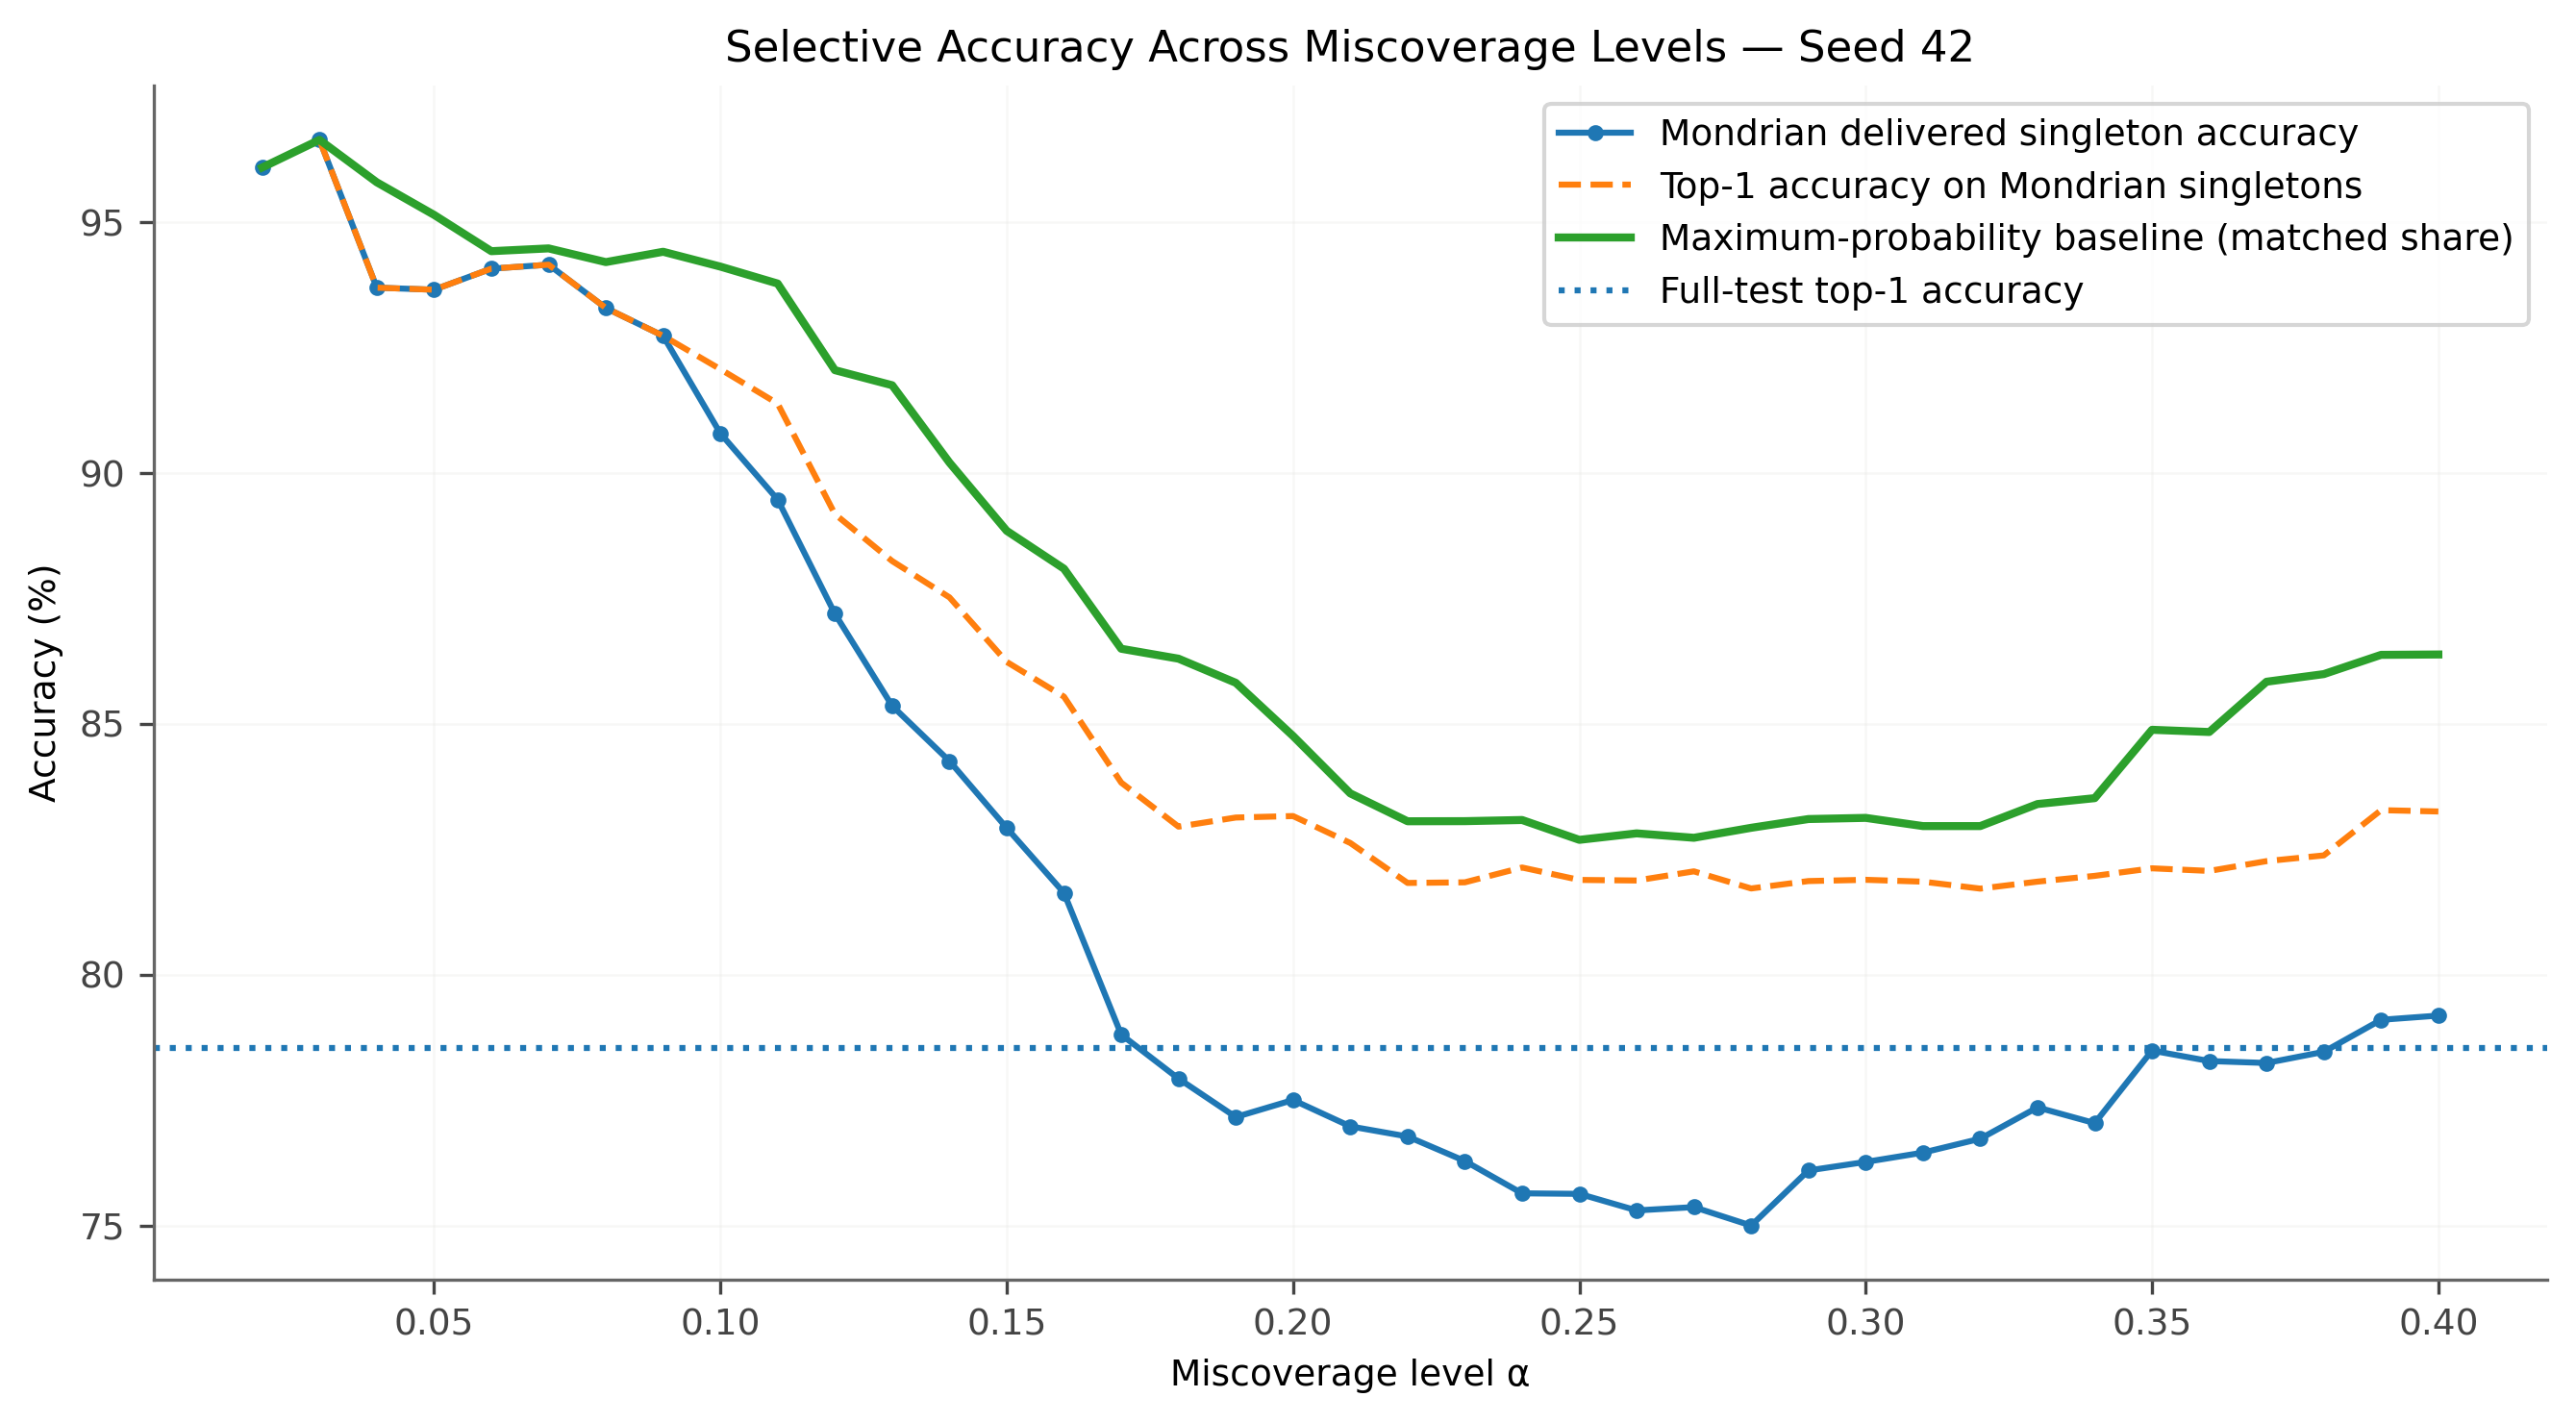

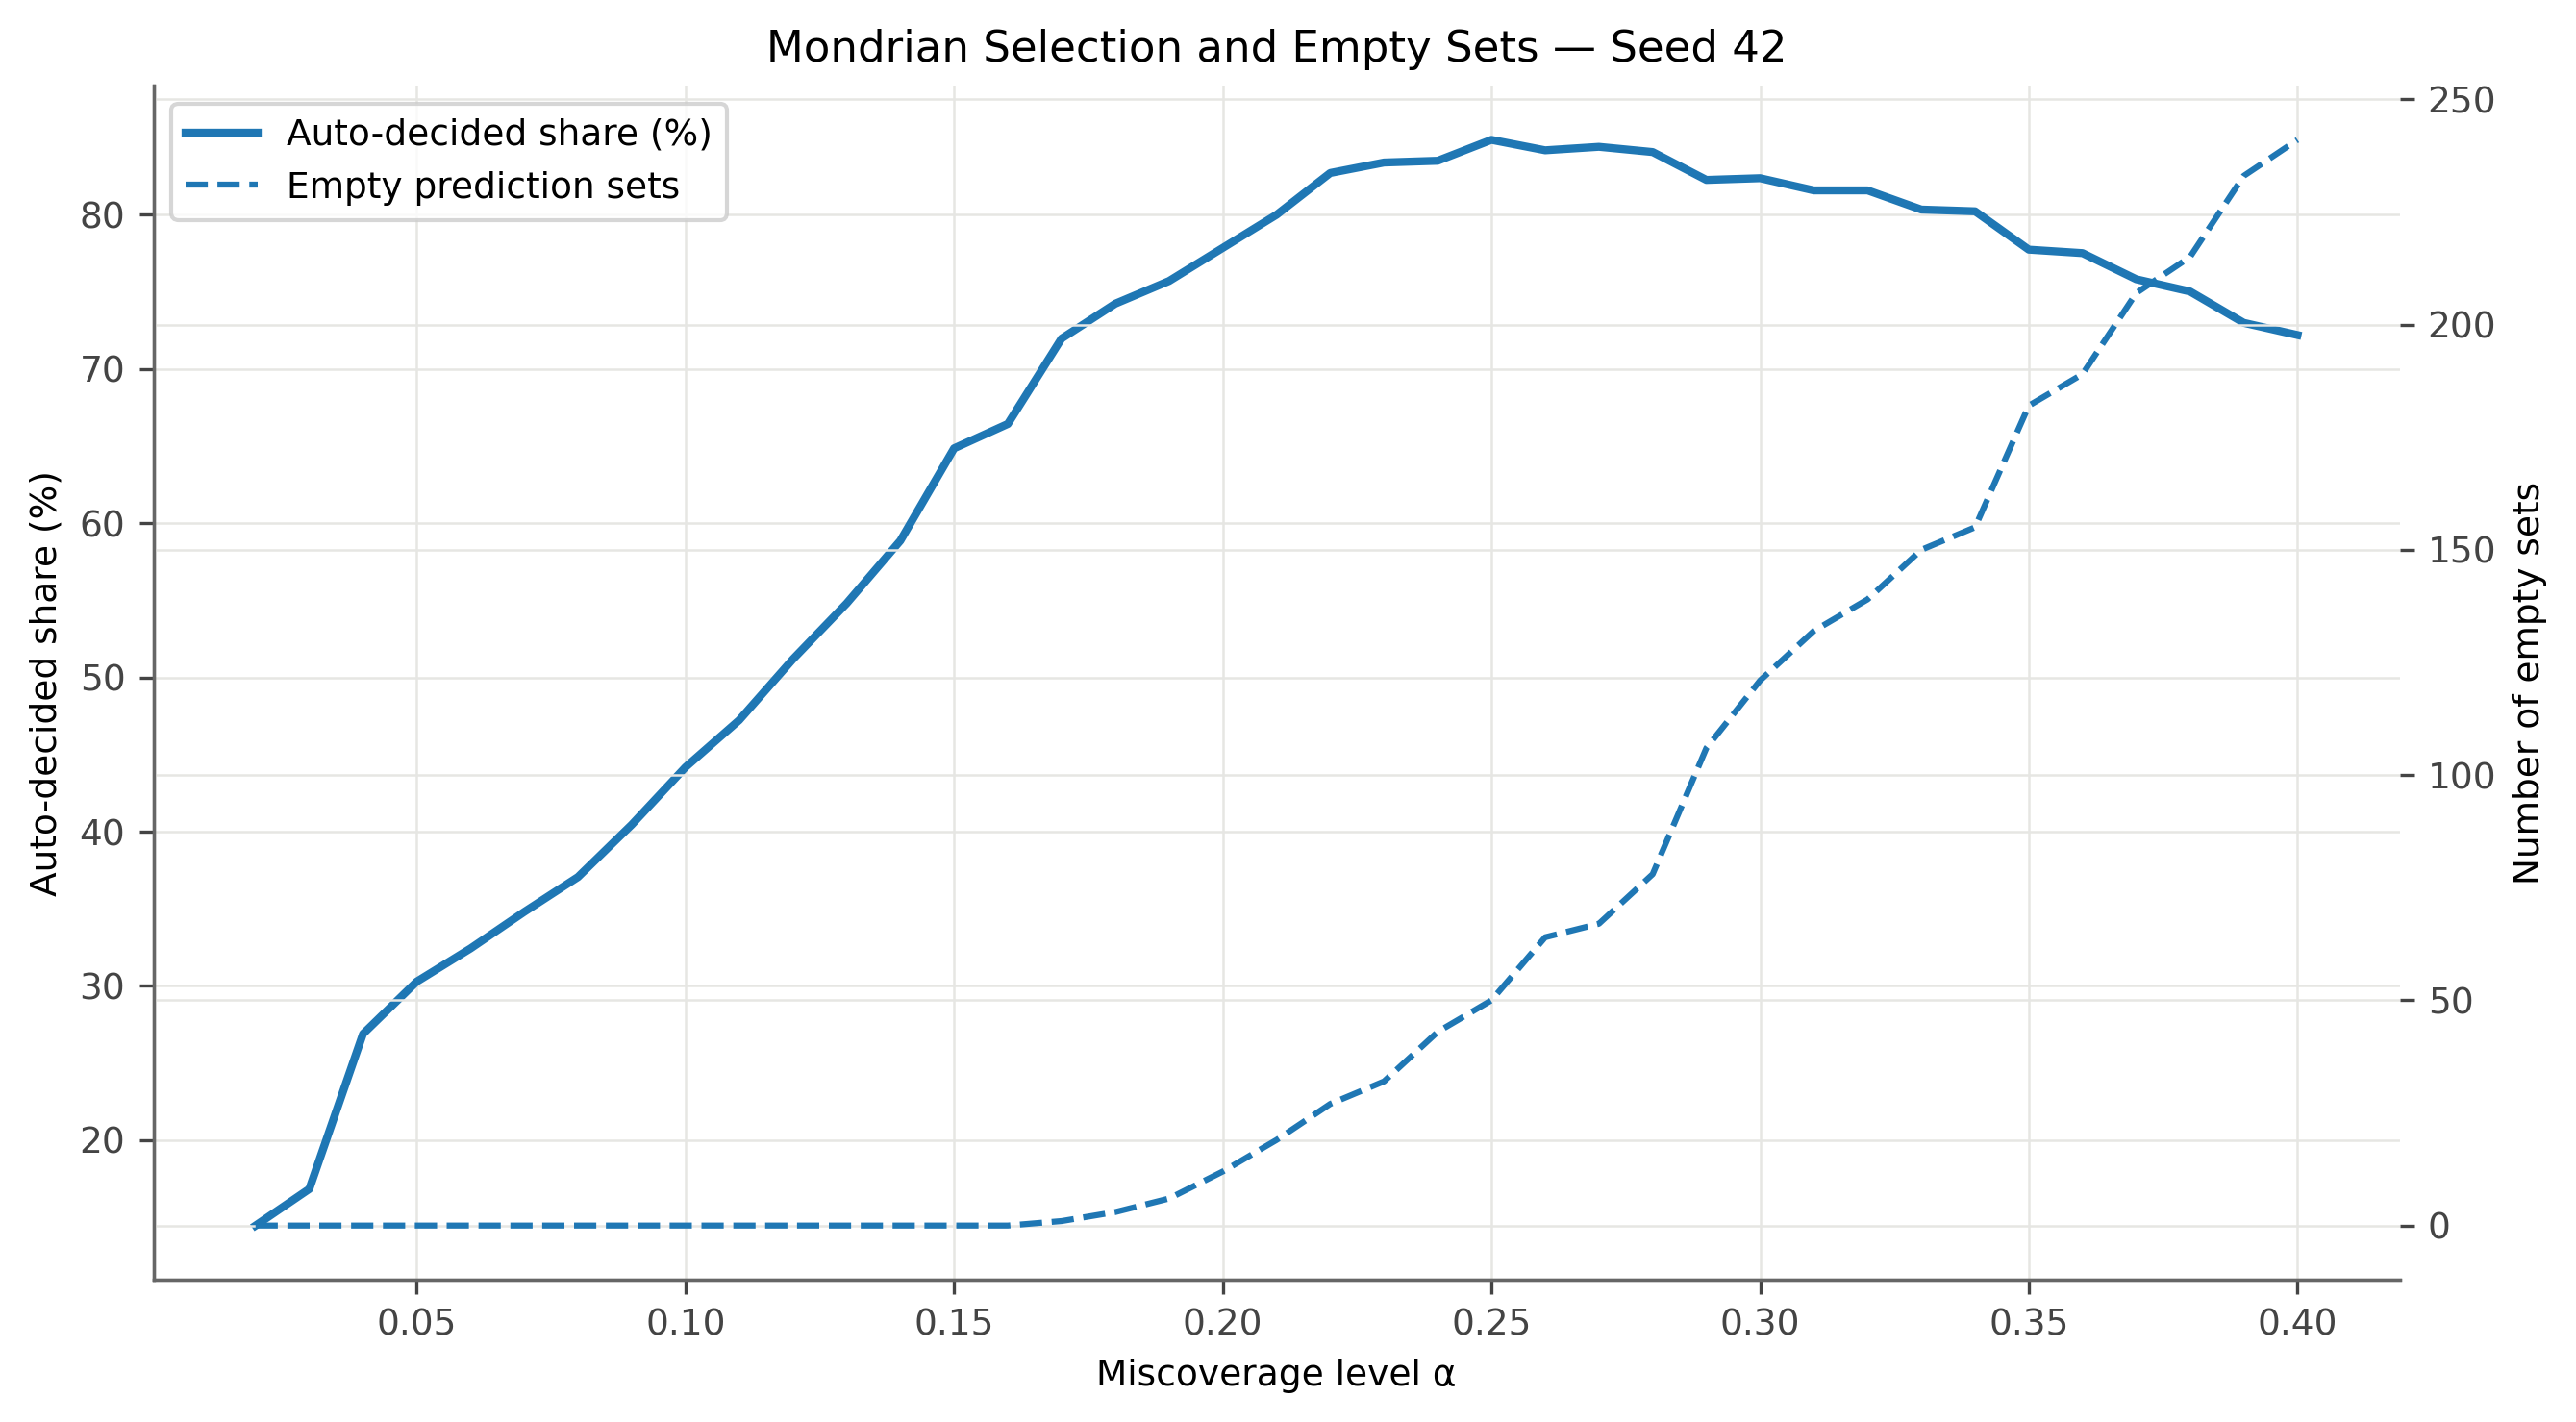


B3 ALPHA SWEEP COMPLETED SUCCESSFULLY!


In [18]:
# ============================================================
# PAPER 3 — B3 ALPHA SWEEP + FIGURE 4
# Jupyter Notebook | Existing X and y
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

SEED = 42
ALPHAS = np.round(np.arange(0.02, 0.401, 0.01), 2)

# ------------------------------------------------------------
# 1. Train model once
# ------------------------------------------------------------

Xtr, Xtmp, ytr, ytmp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)

Xcal, Xte, ycal, yte = train_test_split(
    Xtmp, ytmp, test_size=0.50,
    stratify=ytmp, random_state=SEED
)

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=SEED,
    n_jobs=-1
)

rf.fit(Xtr, ytr)

Pcal = rf.predict_proba(Xcal)
Pte = rf.predict_proba(Xte)

classes = rf.classes_
ycal = np.asarray(ycal)
yte = np.asarray(yte)

class_idx = {c: i for i, c in enumerate(classes)}

cal_idx = np.array([class_idx[c] for c in ycal])
test_idx = np.array([class_idx[c] for c in yte])

cal_scores = 1 - Pcal[np.arange(len(ycal)), cal_idx]

top1_labels = classes[np.argmax(Pte, axis=1)]
max_probs = Pte.max(axis=1)

# Stable ranking for reproducibility
confidence_order = np.argsort(-max_probs, kind="stable")

# ------------------------------------------------------------
# 2. Conformal quantile
# ------------------------------------------------------------

def cp_quantile(scores, alpha):
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return np.partition(scores, k - 1)[k - 1]

# ------------------------------------------------------------
# 3. Evaluate alpha values
# ------------------------------------------------------------

rows = []

for alpha in ALPHAS:

    mondrian_sets = np.zeros_like(Pte, dtype=bool)

    for j, c in enumerate(classes):
        scores_c = cal_scores[ycal == c]
        q_c = cp_quantile(scores_c, alpha)
        mondrian_sets[:, j] = (1 - Pte[:, j]) <= q_c

    sizes = mondrian_sets.sum(axis=1)
    singleton = sizes == 1

    n_auto = int(singleton.sum())

    # Delivered singleton predictions
    if n_auto > 0:
        delivered = classes[
            np.argmax(mondrian_sets[singleton], axis=1)
        ]

        delivered_acc = (
            delivered == yte[singleton]
        ).mean() * 100

        mondrian_top1_acc = (
            top1_labels[singleton] == yte[singleton]
        ).mean() * 100

        # Matched number of selected students
        selected = confidence_order[:n_auto]

        confidence_acc = (
            top1_labels[selected] == yte[selected]
        ).mean() * 100
    else:
        delivered_acc = np.nan
        mondrian_top1_acc = np.nan
        confidence_acc = np.nan

    # Conditional coverage
    covered = mondrian_sets[
        np.arange(len(yte)), test_idx
    ]

    rows.append({
        "Alpha": alpha,
        "Auto_Decided": n_auto,
        "Auto_Share": n_auto / len(yte) * 100,
        "Mondrian_Delivered": delivered_acc,
        "Mondrian_Top1": mondrian_top1_acc,
        "MaxProb_Accuracy": confidence_acc,
        "Empty_Sets": int((sizes == 0).sum()),
        "Overall_Coverage": covered.mean() * 100,
        "Enrolled_Coverage": covered[yte == "Enrolled"].mean() * 100
    })

alpha_results = pd.DataFrame(rows)

print("=" * 75)
print("B3 — ALPHA SWEEP RESULTS")
print("=" * 75)

display(alpha_results.round(2))

# ------------------------------------------------------------
# 4. Supervisor verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("IMPORTANT ALPHA VALUES")
print("=" * 75)

display(
    alpha_results[
        alpha_results["Alpha"].isin(
            [0.02, 0.10, 0.20, 0.25, 0.40]
        )
    ].round(2)
)

print("\nMaximum auto-decided share:")
peak = alpha_results.loc[alpha_results["Auto_Share"].idxmax()]
print(
    f"Alpha = {peak['Alpha']:.2f}; "
    f"Auto-decided = {peak['Auto_Share']:.2f}%"
)

print("\nNumber of alpha values where MaxProb >= Mondrian:")
valid = alpha_results.dropna(
    subset=["MaxProb_Accuracy", "Mondrian_Delivered"]
)

wins = (
    valid["MaxProb_Accuracy"] >= valid["Mondrian_Delivered"]
).sum()

print(f"{wins}/{len(valid)}")

# ------------------------------------------------------------
# 5. Figure 4A — Accuracy comparison
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    alpha_results["Alpha"],
    alpha_results["Mondrian_Delivered"],
    marker="o",
    markersize=3,
    label="Mondrian delivered singleton accuracy"
)

plt.plot(
    alpha_results["Alpha"],
    alpha_results["Mondrian_Top1"],
    linestyle="--",
    label="Top-1 accuracy on Mondrian singletons"
)

plt.plot(
    alpha_results["Alpha"],
    alpha_results["MaxProb_Accuracy"],
    linewidth=2,
    label="Maximum-probability baseline (matched share)"
)

plt.axhline(
    (top1_labels == yte).mean() * 100,
    linestyle=":",
    label="Full-test top-1 accuracy"
)

plt.xlabel("Miscoverage level α")
plt.ylabel("Accuracy (%)")
plt.title("Selective Accuracy Across Miscoverage Levels — Seed 42")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figure4A_accuracy.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 6. Figure 4B — Auto-decided share and empty sets
# ------------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(
    alpha_results["Alpha"],
    alpha_results["Auto_Share"],
    linewidth=2,
    label="Auto-decided share (%)"
)

ax1.set_xlabel("Miscoverage level α")
ax1.set_ylabel("Auto-decided share (%)")

ax2 = ax1.twinx()

ax2.plot(
    alpha_results["Alpha"],
    alpha_results["Empty_Sets"],
    linestyle="--",
    label="Empty prediction sets"
)

ax2.set_ylabel("Number of empty sets")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="best"
)

plt.title("Mondrian Selection and Empty Sets — Seed 42")
plt.tight_layout()
plt.savefig("Figure4B_selection.png", dpi=300)
plt.show()

print("\nB3 ALPHA SWEEP COMPLETED SUCCESSFULLY!")

In [19]:
import numpy as np, pandas as pd, time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

groups = {"Gender":"Gender","Scholarship":"Scholarship holder","Debtor":"Debtor","Displaced":"Displaced","International":"International"}
classes = ["Dropout","Enrolled","Graduate"]
alpha = 0.10
rows = []
start = time.time()

def cpq(s):
    n = len(s)
    k = int(np.ceil((n+1)*(1-alpha)))
    return np.inf if k > n or n == 0 else np.partition(s,k-1)[k-1]

for seed in range(1000,1100):
    Xtr,Xtmp,ytr,ytmp = train_test_split(X,y,test_size=0.4,stratify=y,random_state=seed)
    Xcal,Xte,ycal,yte = train_test_split(Xtmp,ytmp,test_size=0.5,stratify=ytmp,random_state=seed)
    rf = RandomForestClassifier(n_estimators=500,random_state=seed,n_jobs=-1).fit(Xtr,ytr)
    pc,pt = rf.predict_proba(Xcal),rf.predict_proba(Xte)
    yc,yt = np.asarray(ycal),np.asarray(yte)
    ci = {c:i for i,c in enumerate(rf.classes_)}
    scores = 1-pc[np.arange(len(yc)),[ci[c] for c in yc]]
    standard = (1-pt)<=cpq(scores)

    for attr,col in groups.items():
        gc,gt = np.asarray(Xcal[col]),np.asarray(Xte[col])
        group_sets = np.zeros_like(pt,dtype=bool)
        intersection = np.zeros_like(pt,dtype=bool)

        for g in np.unique(gt):
            mc,mt = gc==g,gt==g
            group_sets[mt] = (1-pt[mt])<=cpq(scores[mc])
            for c,j in ci.items():
                intersection[mt,j] = (1-pt[mt,j])<=cpq(scores[mc & (yc==c)])

        for method,S in [("Split CP",standard),("Group CP",group_sets),("Group x Label CP",intersection)]:
            covered = S[np.arange(len(yt)),[ci[c] for c in yt]]
            sizes = S.sum(axis=1)

            for g in np.unique(gt):
                for c in ["Overall"]+classes:
                    mask = (gt==g) if c=="Overall" else ((gt==g)&(yt==c))
                    if not mask.any(): continue
                    ncal = np.sum(gc==g) if c=="Overall" else np.sum((gc==g)&(yc==c))
                    rows.append([seed,attr,g,c,method,int(mask.sum()),int(ncal),covered[mask].mean()*100,sizes[mask].mean()])

    if (seed-999)%10==0:
        print(f"Completed {seed-999}/100",flush=True)

b5 = pd.DataFrame(rows,columns=["Seed","Attribute","Group","Class","Method","N_Test","N_Cal","Coverage","Set_Size"])
b5_summary = b5.groupby(["Attribute","Group","Class","Method"],as_index=False).agg(
    Mean_Coverage=("Coverage","mean"),
    SD=("Coverage","std"),
    Mean_Set_Size=("Set_Size","mean"),
    Mean_N_Cal=("N_Cal","mean"),
    Partitions=("Seed","nunique"),
    Below_90=("Coverage",lambda v:int((v<90).sum()))
)

print("\nGROUP COVERAGE RESULTS")
display(b5_summary[b5_summary["Class"]=="Overall"].round(2))

print("\nGROUP x LABEL RESULTS")
display(b5_summary[b5_summary["Class"]!="Overall"].round(2))

b5.to_csv("B5_full_results.csv",index=False)
b5_summary.to_csv("B5_summary.csv",index=False)

print("\nCompleted in",round((time.time()-start)/60,2),"minutes")

Completed 10/100
Completed 20/100
Completed 30/100
Completed 40/100
Completed 50/100
Completed 60/100
Completed 70/100
Completed 80/100
Completed 90/100
Completed 100/100

GROUP COVERAGE RESULTS


,Attribute,Group,Class,Method,Mean_Coverage,SD,Mean_Set_Size,Mean_N_Cal,Partitions,Below_90
9,Debtor,0,Overall,Group CP,90.27,1.55,1.42,785.52,100,42
10,Debtor,0,Overall,Group x Label CP,90.45,1.38,1.64,785.52,100,32
11,Debtor,0,Overall,Split CP,90.17,1.55,1.42,785.52,100,45
21,Debtor,1,Overall,Group CP,91.24,3.60,1.52,99.48,100,36
22,Debtor,1,Overall,Group x Label CP,92.03,3.49,1.81,99.48,100,26
23,Debtor,1,Overall,Split CP,90.91,2.70,1.49,99.48,100,34
33,Displaced,0,Overall,Group CP,90.34,2.45,1.37,399.61,100,44
34,Displaced,0,Overall,Group x Label CP,90.85,2.05,1.53,399.61,100,35
35,Displaced,0,Overall,Split CP,91.56,1.87,1.42,399.61,100,22
45,Displaced,1,Overall,Group CP,90.22,1.98,1.49,485.39,100,42



GROUP x LABEL RESULTS


,Attribute,Group,Class,Method,Mean_Coverage,SD,Mean_Set_Size,Mean_N_Cal,Partitions,Below_90
0,Debtor,0,Dropout,Group CP,85.93,2.46,1.43,223.52,100,97
1,Debtor,0,Dropout,Group x Label CP,90.42,2.59,1.61,223.52,100,39
2,Debtor,0,Dropout,Split CP,85.82,2.51,1.43,223.52,100,97
3,Debtor,0,Enrolled,Group CP,72.21,5.74,1.87,140.81,100,100
4,Debtor,0,Enrolled,Group x Label CP,90.56,3.51,1.94,140.81,100,39
...,...,...,...,...,...,...,...,...,...,...
112,Scholarship,1,Enrolled,Group x Label CP,91.46,7.81,2.19,26.66,100,33
113,Scholarship,1,Enrolled,Split CP,60.79,9.97,1.78,26.66,100,100
114,Scholarship,1,Graduate,Group CP,99.12,0.99,1.15,166.62,100,0
115,Scholarship,1,Graduate,Group x Label CP,90.56,3.46,1.97,166.62,100,38



Completed in 6.85 minutes


In [20]:
import numpy as np, pandas as pd, time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from IPython.display import display

seeds = range(1000,1100)
alpha = 0.10
rows = []
start = time.time()

def cq(s):
    n = len(s)
    k = int(np.ceil((n+1)*(1-alpha)))
    return np.inf if n == 0 or k > n else np.partition(s,k-1)[k-1]

for seed in seeds:
    Xtr,Xtmp,ytr,ytmp = train_test_split(X,y,test_size=0.4,stratify=y,random_state=seed)
    Xcal,Xte,ycal,yte = train_test_split(Xtmp,ytmp,test_size=0.5,stratify=ytmp,random_state=seed)
    rf = RandomForestClassifier(n_estimators=500,random_state=seed,n_jobs=-1).fit(Xtr,ytr)

    pc,pt = rf.predict_proba(Xcal),rf.predict_proba(Xte)
    yc,yt = np.asarray(ycal),np.asarray(yte)
    cls = rf.classes_
    idx = {c:i for i,c in enumerate(cls)}
    ci = np.array([idx[c] for c in yc])
    ti = np.array([idx[c] for c in yt])
    scores = 1-pc[np.arange(len(yc)),ci]

    a,b = train_test_split(np.arange(len(yc)),test_size=0.75,stratify=yc,random_state=seed)
    emb = np.array([np.quantile(scores[a][yc[a]==c],[.1,.25,.5,.75,.9]) for c in cls])
    km = KMeans(n_clusters=2,random_state=seed,n_init=10).fit(emb)
    clusters = km.labels_

    qglobal = cq(scores[b])
    qclass = np.array([cq(scores[b][yc[b]==c]) for c in cls])
    qcluster = np.array([cq(scores[b][clusters[ci[b]]==k]) for k in range(2)])

    methods = {
        "Split CP": np.repeat(qglobal,len(cls)),
        "Classwise CP": qclass,
        "Clustered CP": qcluster[clusters]
    }

    for name,q in methods.items():
        S = (1-pt)<=q
        covered = S[np.arange(len(yt)),ti]
        sizes = S.sum(axis=1)

        for c in ["Overall"]+list(cls):
            mask = np.ones(len(yt),dtype=bool) if c=="Overall" else yt==c
            rows.append([seed,name,c,covered[mask].mean()*100,sizes[mask].mean(),int((sizes[mask]==0).sum())])

    if (seed-999)%10==0:
        print(f"Completed {seed-999}/100",flush=True)

cluster_df = pd.DataFrame(rows,columns=["Seed","Method","Class","Coverage","Set_Size","Empty"])
cluster_summary = cluster_df.groupby(["Method","Class"],as_index=False).agg(
    Mean_Coverage=("Coverage","mean"),
    SD=("Coverage","std"),
    Mean_Set_Size=("Set_Size","mean"),
    Mean_Empty=("Empty","mean"),
    Below_90=("Coverage",lambda x:int((x<90).sum()))
)

print("\nCLUSTERED CP COMPARISON")
display(cluster_summary.round(3))

cluster_df.to_csv("B5_clustered_full.csv",index=False)
cluster_summary.to_csv("B5_clustered_summary.csv",index=False)

print("\nCompleted in",round((time.time()-start)/60,2),"minutes")

C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMe

Completed 10/100


C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMe

Completed 20/100


C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMe

Completed 30/100


... (13 outputs left out)

Completed 100/100

CLUSTERED CP COMPARISON


C:\Users\Laptop Solutions\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Method,Class,Mean_Coverage,SD,Mean_Set_Size,Mean_Empty,Below_90
0,Classwise CP,Dropout,90.338,2.434,1.593,0.0,38
1,Classwise CP,Enrolled,90.453,3.459,1.878,0.0,43
2,Classwise CP,Graduate,90.344,2.093,1.513,0.0,41
3,Classwise CP,Overall,90.362,1.411,1.604,0.0,45
4,Clustered CP,Dropout,82.000,2.878,1.557,0.0,100
5,Clustered CP,Enrolled,90.453,3.459,1.750,0.0,43
6,Clustered CP,Graduate,95.523,1.330,1.460,0.0,0
7,Clustered CP,Overall,90.272,1.466,1.543,0.0,41
8,Split CP,Dropout,87.944,2.136,1.408,0.0,84
9,Split CP,Enrolled,71.434,6.064,1.874,0.0,100



Completed in 7.27 minutes


In [21]:
import numpy as np, pandas as pd, time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

seeds_b6 = range(1000,1100)
alpha_b6 = 0.10
rows_b6 = []
start_b6 = time.time()

def cq_b6(s):
    s = np.asarray(s)
    n = len(s)
    k = int(np.ceil((n+1)*(1-alpha_b6)))
    return np.inf if n == 0 or k > n else np.partition(s,k-1)[k-1]

for seed in seeds_b6:
    Xtr,Xtmp,ytr,ytmp = train_test_split(X,y,test_size=0.40,stratify=y,random_state=seed)
    Xcal,Xte,ycal,yte = train_test_split(Xtmp,ytmp,test_size=0.50,stratify=ytmp,random_state=seed)
    rf = RandomForestClassifier(n_estimators=500,random_state=seed,n_jobs=-1).fit(Xtr,ytr)
    pc,pt = rf.predict_proba(Xcal),rf.predict_proba(Xte)
    yc,yt = np.asarray(ycal),np.asarray(yte)
    cls = rf.classes_
    idx = {c:i for i,c in enumerate(cls)}
    ci = np.array([idx[c] for c in yc])
    ti = np.array([idx[c] for c in yt])
    scores = 1-pc[np.arange(len(yc)),ci]

    for share in [0.25,0.50,1.00]:
        if share == 1.00:
            selected = np.arange(len(yc))
        else:
            selected,_ = train_test_split(
                np.arange(len(yc)),train_size=share,stratify=yc,random_state=seed
            )

        sc,ys = scores[selected],yc[selected]
        qsplit = cq_b6(sc)
        qmond = np.array([cq_b6(sc[ys==c]) for c in cls])

        for method,q in [("Split CP",np.repeat(qsplit,len(cls))),("Mondrian CP",qmond)]:
            S = (1-pt)<=q
            covered = S[np.arange(len(yt)),ti]
            sizes = S.sum(axis=1)

            for c in ["Overall"]+list(cls):
                mask = np.ones(len(yt),dtype=bool) if c=="Overall" else yt==c
                rows_b6.append([seed,share,len(selected),len(Xtr),len(Xte),method,c,
                                covered[mask].mean()*100,sizes[mask].mean(),
                                int((sizes[mask]==0).sum())])

    if (seed-999)%10==0:
        print(f"Completed {seed-999}/100",flush=True)

b6 = pd.DataFrame(rows_b6,columns=[
    "Seed","Calibration_Share","N_Cal","N_Train","N_Test",
    "Method","Class","Coverage","Set_Size","Empty_Sets"
])

b6_summary = b6.groupby(["Calibration_Share","Method","Class"],as_index=False).agg(
    Mean_N_Cal=("N_Cal","mean"),
    Mean_Coverage=("Coverage","mean"),
    SD=("Coverage","std"),
    Mean_Set_Size=("Set_Size","mean"),
    Below_90=("Coverage",lambda v:int((v<90).sum())),
    Mean_Empty=("Empty_Sets","mean")
)

print("\nB6 — FIXED-TRAINING CALIBRATION RESULTS")
display(b6_summary.round(3))

print("\nB6 — ENROLLED COVERAGE COMPARISON")
display(b6_summary[b6_summary["Class"]=="Enrolled"].round(3))

b6.to_csv("B6_full_results.csv",index=False)
b6_summary.to_csv("B6_summary.csv",index=False)

print("\nCompleted in",round((time.time()-start_b6)/60,2),"minutes")

Completed 10/100
Completed 20/100
Completed 30/100
Completed 40/100
Completed 50/100
Completed 60/100
Completed 70/100
Completed 80/100
Completed 90/100
Completed 100/100

B6 — FIXED-TRAINING CALIBRATION RESULTS


,Calibration_Share,Method,Class,Mean_N_Cal,Mean_Coverage,SD,Mean_Set_Size,Below_90,Mean_Empty
0,0.25,Mondrian CP,Dropout,221.0,91.454,3.804,1.602,28,0.0
1,0.25,Mondrian CP,Enrolled,221.0,90.201,5.170,1.934,43,0.0
2,0.25,Mondrian CP,Graduate,221.0,90.213,3.210,1.577,42,0.0
3,0.25,Mondrian CP,Overall,221.0,90.609,2.171,1.649,36,0.0
4,0.25,Split CP,Dropout,221.0,88.511,2.572,1.440,69,0.0
5,0.25,Split CP,Enrolled,221.0,73.094,7.173,1.922,100,0.0
6,0.25,Split CP,Graduate,221.0,98.457,0.789,1.303,0,0.0
7,0.25,Split CP,Overall,221.0,90.708,2.159,1.458,36,0.0
8,0.50,Mondrian CP,Dropout,442.0,90.972,2.796,1.600,35,0.0
9,0.50,Mondrian CP,Enrolled,442.0,90.516,4.069,1.910,39,0.0



B6 — ENROLLED COVERAGE COMPARISON


,Calibration_Share,Method,Class,Mean_N_Cal,Mean_Coverage,SD,Mean_Set_Size,Below_90,Mean_Empty
1,0.25,Mondrian CP,Enrolled,221.0,90.201,5.170,1.934,43,0.0
5,0.25,Split CP,Enrolled,221.0,73.094,7.173,1.922,100,0.0
9,0.50,Mondrian CP,Enrolled,442.0,90.516,4.069,1.910,39,0.0
13,0.50,Split CP,Enrolled,442.0,71.918,6.149,1.887,100,0.0
17,1.00,Mondrian CP,Enrolled,885.0,90.270,3.286,1.885,44,0.0
21,1.00,Split CP,Enrolled,885.0,71.730,5.606,1.880,100,0.0



Completed in 6.94 minutes


In [25]:
print(results_df_b3.columns.tolist())
display(results_df_b3.head(3))

['Seed', 'Test_Size', 'Auto_Decided', 'Auto_Decided_Share', 'Mondrian_Delivered_Accuracy', 'Mondrian_Top1_Accuracy', 'MaxProb_Accuracy', 'Empty_Sets', 'Mean_Set_Size', 'Mondrian_Referred_Dropout', 'MaxProb_Referred_Dropout', 'Mondrian_Referred_Enrolled', 'MaxProb_Referred_Enrolled', 'Mondrian_Referred_Graduate', 'MaxProb_Referred_Graduate']


,Seed,Test_Size,Auto_Decided,Auto_Decided_Share,Mondrian_Delivered_Accuracy,Mondrian_Top1_Accuracy,MaxProb_Accuracy,Empty_Sets,Mean_Set_Size,Mondrian_Referred_Dropout,MaxProb_Referred_Dropout,Mondrian_Referred_Enrolled,MaxProb_Referred_Enrolled,Mondrian_Referred_Graduate,MaxProb_Referred_Graduate
0,1000,885,329,37.175141,94.528875,94.528875,95.136778,0,1.724294,176,156,144,149,236,251
1,1001,885,474,53.559322,88.607595,89.029536,90.295359,0,1.492655,144,130,117,125,150,156
2,1002,885,420,47.457627,94.523810,94.047619,95.714286,0,1.572881,147,140,137,149,181,176


In [26]:
import numpy as np, pandas as pd
from IPython.display import display

d = results_df_b3.copy()
diff = d["Mondrian_Delivered_Accuracy"] - d["Mondrian_Top1_Accuracy"]

paired_b3 = pd.DataFrame({
    "Metric":["Delivered - Same-student Top1","MaxProb - Delivered"],
    "Mean_Difference":[diff.mean(),(d["MaxProb_Accuracy"]-d["Mondrian_Delivered_Accuracy"]).mean()],
    "SD_Difference":[diff.std(ddof=1),(d["MaxProb_Accuracy"]-d["Mondrian_Delivered_Accuracy"]).std(ddof=1)],
    "Nonzero_Partitions":[int((abs(diff)>1e-9).sum()),int((abs(d["MaxProb_Accuracy"]-d["Mondrian_Delivered_Accuracy"])>1e-9).sum())],
    "Total_Partitions":[len(d),len(d)]
})

ref_cols = ["Dropout","Enrolled","Graduate"]
ref_rows = []

for method in ["Mondrian","MaxProb"]:
    counts = np.array([d[f"{method}_Referred_{c}"].sum() for c in ref_cols])
    total = counts.sum()
    for c,n in zip(ref_cols,counts):
        ref_rows.append([method,c,int(n),int(total),100*n/total])

referral_b3 = pd.DataFrame(ref_rows,columns=["Method","Class","Referred_Count","Total_Referred","Referral_Share"])

print("PAIRED SINGLETON COMPARISON")
display(paired_b3.round(4))

print("REFERRAL COMPOSITION")
display(referral_b3.round(3))

print("CHECK REFERRAL DENOMINATORS")
print("Mondrian:",(d[[f"Mondrian_Referred_{c}" for c in ref_cols]].sum(axis=1)==d["Test_Size"]-d["Auto_Decided"]).all())
print("MaxProb:",(d[[f"MaxProb_Referred_{c}" for c in ref_cols]].sum(axis=1)==d["Test_Size"]-d["Auto_Decided"]).all())

paired_b3.to_csv("B3_paired_verified.csv",index=False)
referral_b3.to_csv("B3_referrals_verified.csv",index=False)

PAIRED SINGLETON COMPARISON


,Metric,Mean_Difference,SD_Difference,Nonzero_Partitions,Total_Partitions
0,Delivered - Same-student Top1,0.0003,0.6095,71,100
1,MaxProb - Delivered,2.6033,1.6180,98,100


REFERRAL COMPOSITION


,Method,Class,Referred_Count,Total_Referred,Referral_Share
0,Mondrian,Dropout,15870,49411,32.118
1,Mondrian,Enrolled,13136,49411,26.585
2,Mondrian,Graduate,20405,49411,41.296
3,MaxProb,Dropout,14529,49411,29.404
4,MaxProb,Enrolled,14210,49411,28.759
5,MaxProb,Graduate,20672,49411,41.837


CHECK REFERRAL DENOMINATORS
Mondrian: True
MaxProb: True


In [33]:
import numpy as np
import pandas as pd
import time
from pathlib import Path

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

seeds = [42, 1, 7, 13, 21, 55, 77, 99, 123, 2024]

params = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rows = []
best_params_rows = []
start = time.time()

def conformal_quantile(scores, alpha=0.10):
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.inf if n == 0 or k > n else np.partition(scores, k - 1)[k - 1]

for i, seed in enumerate(seeds, 1):

    Xtr, Xtmp, ytr, ytmp = train_test_split(
        X, y, test_size=0.4, stratify=y, random_state=seed
    )

    Xcal, Xte, ycal, yte = train_test_split(
        Xtmp, ytmp, test_size=0.5, stratify=ytmp, random_state=seed
    )

    cv = StratifiedKFold(
        n_splits=3, shuffle=True, random_state=seed
    )

    search = RandomizedSearchCV(
        estimator=RandomForestClassifier(
            random_state=seed, n_jobs=1
        ),
        param_distributions=params,
        n_iter=10,
        scoring="f1_macro",
        cv=cv,
        random_state=seed,
        n_jobs=-1,
        refit=True
    )

    search.fit(Xtr, ytr)

    best_params_rows.append({
        "Seed": seed,
        "Best_Params": str(search.best_params_),
        "CV_Macro_F1": search.best_score_
    })

    models = {
        "Default RF": RandomForestClassifier(
            n_estimators=500, random_state=seed, n_jobs=-1
        ),
        "Tuned RF": search.best_estimator_
    }

    for name, model in models.items():

        if name == "Default RF":
            model.fit(Xtr, ytr)

        pc = model.predict_proba(Xcal)
        pt = model.predict_proba(Xte)

        yc = np.asarray(ycal)
        yt = np.asarray(yte)

        classes = model.classes_
        ix = {c: j for j, c in enumerate(classes)}

        ci = np.array([ix[c] for c in yc])
        ti = np.array([ix[c] for c in yt])

        scores = 1 - pc[np.arange(len(yc)), ci]

        qsplit = conformal_quantile(scores)

        qmond = np.array([
            conformal_quantile(scores[yc == c])
            for c in classes
        ])

        predictions = model.predict(Xte)

        acc = accuracy_score(yt, predictions) * 100
        f1 = f1_score(yt, predictions, average="macro") * 100

        for method, q in [
            ("Split CP", np.repeat(qsplit, len(classes))),
            ("Mondrian CP", qmond)
        ]:

            S = (1 - pt) <= q

            hit = S[np.arange(len(yt)), ti]
            sizes = S.sum(axis=1)

            for c in ["Overall"] + list(classes):

                mask = (
                    np.ones(len(yt), dtype=bool)
                    if c == "Overall"
                    else yt == c
                )

                rows.append([
                    seed, name, method, c,
                    hit[mask].mean() * 100,
                    sizes[mask].mean(),
                    acc, f1
                ])

    rf_cv_df = pd.DataFrame(
        rows,
        columns=[
            "Seed", "Model", "Method", "Class",
            "Coverage", "Set_Size", "Accuracy", "Macro_F1"
        ]
    )

    rf_cv_df.to_csv(
        "RF_training_only_tuning_10seeds.csv",
        index=False
    )

    pd.DataFrame(best_params_rows).to_csv(
        "RF_best_parameters_10seeds.csv",
        index=False
    )

    print(f"Completed {i}/10 | Seed: {seed}", flush=True)

rf_cv_summary = rf_cv_df.groupby(
    ["Model", "Method", "Class"],
    as_index=False
).agg(
    Mean_Coverage=("Coverage", "mean"),
    SD=("Coverage", "std"),
    Mean_Set_Size=("Set_Size", "mean"),
    Accuracy=("Accuracy", "mean"),
    Macro_F1=("Macro_F1", "mean"),
    Below_90=("Coverage", lambda x: int((x < 90).sum()))
)

print("\nFINAL 10-SEED SUMMARY")
display(rf_cv_summary.round(3))

rf_cv_summary.to_csv(
    "RF_training_only_tuning_summary.csv",
    index=False
)

print("\nTOTAL SEEDS:", rf_cv_df["Seed"].nunique())
print("TOTAL ROWS:", len(rf_cv_df))
print("FINISHED!")

Completed 1/10 | Seed: 42
Completed 2/10 | Seed: 1
Completed 3/10 | Seed: 7
Completed 4/10 | Seed: 13
Completed 5/10 | Seed: 21
Completed 6/10 | Seed: 55
Completed 7/10 | Seed: 77
Completed 8/10 | Seed: 99
Completed 9/10 | Seed: 123
Completed 10/10 | Seed: 2024

FINAL 10-SEED SUMMARY


,Model,Method,Class,Mean_Coverage,SD,Mean_Set_Size,Accuracy,Macro_F1,Below_90
0,Default RF,Mondrian CP,Dropout,89.542,2.561,1.584,76.350,68.055,5
1,Default RF,Mondrian CP,Enrolled,89.937,1.852,1.886,76.350,68.055,8
2,Default RF,Mondrian CP,Graduate,88.982,1.315,1.514,76.350,68.055,8
3,Default RF,Mondrian CP,Overall,89.333,1.085,1.603,76.350,68.055,7
4,Default RF,Split CP,Dropout,86.655,2.109,1.419,76.350,68.055,9
5,Default RF,Split CP,Enrolled,73.145,4.193,1.878,76.350,68.055,10
6,Default RF,Split CP,Graduate,98.213,0.470,1.296,76.350,68.055,0
7,Default RF,Split CP,Overall,90.000,1.237,1.440,76.350,68.055,6
8,Tuned RF,Mondrian CP,Dropout,89.789,2.288,1.586,76.158,67.464,5
9,Tuned RF,Mondrian CP,Enrolled,90.189,1.832,1.906,76.158,67.464,6



TOTAL SEEDS: 10
TOTAL ROWS: 160
FINISHED!
